In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from Load_CCSB_Data import GetOrfMapping
from load_edgotyping_data import load_qY2H
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from Load_CCSB_Data import GetHI2018_paper

In [3]:
from matplotlib import ticker

In [4]:
from scipy.stats import pearsonr, spearmanr, linregress

## Load Data

### Functionnal data

#### ClinVar

In [5]:
summary_df = pd.read_csv('/Users/georgescoppin/Documents/PhD/CCSB/ClinVar/variant_summary-3.txt',sep='\t',skiprows=0, low_memory=False)
summary_df = summary_df[summary_df.Assembly == 'GRCh38'].copy()
summary_df.rename(columns={w:w.replace('#','').replace('(','').replace(')','').replace('/','') for w in summary_df.columns},inplace=True)
summary_df.head()

,AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS dbSNP,nsvesv dbVar,RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF
1,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic,1,-,397704705,-,RCV000000012,"MONDO:MONDO:0013342,MedGen:C3150901,OMIM:61364...",Hereditary spastic paraplegia 48,germline;unknown,germline,GRCh38,NC_000007.14,7,4781213,4781216,na,na,7p22.1,"criteria provided, single submitter",2,-,N,"ClinGen:CA215070,OMIM:613653.0001",3,2,4781213,GGAT,TGCTGTAAACTGTAACTGTAAA
3,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,-,RCV000000013,"MONDO:MONDO:0013342,MedGen:C3150901,OMIM:61364...",Hereditary spastic paraplegia 48,germline,germline,GRCh38,NC_000007.14,7,4787730,4787743,na,na,7p22.1,no assertion criteria provided,1,-,N,"ClinGen:CA215072,OMIM:613653.0002",1,3,4787729,GCTGCTGGACCTGCC,G
5,15043,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,-,RCV000000014,"MONDO:MONDO:0033005,MedGen:C4551772,OMIM:25130...",Galloway-Mowat syndrome 1,germline,germline,GRCh38,NC_000015.10,15,84799209,84799209,na,na,15q25.3,no assertion criteria provided,1,-,N,"OMIM:613624.0001,ClinGen:CA210674,UniProtKB:Q9...",1,4,84799209,G,A
7,15044,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Jun 28, 2022",267606829,-,RCV000000015|RCV000578659|RCV001194045,"MONDO:MONDO:0032624,MedGen:C4748791,OMIM:61824...","Mitochondrial complex 1 deficiency, nuclear ty...",germline;unknown,germline,GRCh38,NC_000011.10,11,126275389,126275389,na,na,11q24.2,"criteria provided, multiple submitters, no con...",5,-,N,"ClinGen:CA113792,OMIM:613622.0001",3,5,126275389,C,T
9,15045,single nucleotide variant,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Oct 01, 2010",267606830,-,RCV000000016,"MONDO:MONDO:0032624,MedGen:C4748791,OMIM:618241","Mitochondrial complex 1 deficiency, nuclear ty...",germline,germline,GRCh38,NC_000011.10,11,126277517,126277517,na,na,11q24.2,no assertion criteria provided,1,-,N,"ClinGen:CA113794,UniProtKB:Q96CU9#VAR_064571,O...",1,6,126277517,A,G


In [6]:
cs_vsimple_d = {"Affects":'other',
    "Affects; association":'other',
    "Affects; risk factor":'other',
    "Benign":'Benign',
    "Benign/Likely benign":'Benign',
    "Benign/Likely benign; drug response":'Benign',
    "Benign/Likely benign; drug response; other":'Benign',
    "Benign/Likely benign; other":'Benign',
    "Benign/Likely benign; other; risk factor":'Benign',
    "Benign/Likely benign; risk factor":'Benign',
    "Benign; association":'Benign',
    "Benign; association; confers sensitivity":'Benign',
    "Benign; confers sensitivity":'Benign',
    "Benign; drug response":'Benign',
    "Benign; other":'Benign',
    "Benign; protective":'Benign',
    "Benign; risk factor":'Benign',
    "Conflicting interpretations of pathogenicity":'Conflicting',
    "Conflicting interpretations of pathogenicity; Affects":'Conflicting',
    "Conflicting interpretations of pathogenicity; association":'Conflicting',
    "Conflicting interpretations of pathogenicity; association; risk factor":'Conflicting',
    "Conflicting interpretations of pathogenicity; drug response":'Conflicting',
    "Conflicting interpretations of pathogenicity; drug response; other":'Conflicting',
    "Conflicting interpretations of pathogenicity; other":'Conflicting',
    "Conflicting interpretations of pathogenicity; other; risk factor":'Conflicting',
    "Conflicting interpretations of pathogenicity; protective":'Conflicting',
    "Conflicting interpretations of pathogenicity; risk factor":'Conflicting',
    "Likely benign":'Benign',
    "Likely benign; drug response; other":'Benign',
    "Likely benign; other":'Benign',
    "Likely benign; risk factor":'Benign',
    "Likely pathogenic":'Pathogenic',
    "Likely pathogenic; Affects":'Pathogenic',
    "Likely pathogenic; association":'Pathogenic',
    "Likely pathogenic; drug response":'Pathogenic',
    "Likely pathogenic; other":'Pathogenic',
    "Likely pathogenic; risk factor":'Pathogenic',
    "Likely risk allele":'other',
    "Pathogenic":'Pathogenic',
    "Pathogenic/Likely pathogenic":'Pathogenic',
    "Pathogenic/Likely pathogenic; drug response":'Pathogenic',
    "Pathogenic/Likely pathogenic; other":'Pathogenic',
    "Pathogenic/Likely pathogenic; risk factor":'Pathogenic',
    "Pathogenic; Affects":'Pathogenic',
    "Pathogenic; association":'Pathogenic',
    "Pathogenic; association; protective":'Pathogenic',
    "Pathogenic; confers sensitivity":'Pathogenic',
    "Pathogenic; drug response":'Pathogenic',
    "Pathogenic; drug response; other":'Pathogenic',
    "Pathogenic; other":'Pathogenic',
    "Pathogenic; protective":'Pathogenic',
    "Pathogenic; risk factor":'Pathogenic',
    "Uncertain significance":'VUS',
    "Uncertain significance; Affects":'VUS',
    "Uncertain significance; Pathogenic/Likely pathogenic":'VUS',
    "Uncertain significance; association":'VUS',
    "Uncertain significance; drug response":'VUS',
    "Uncertain significance; other":'VUS',
    "Uncertain significance; risk factor":'VUS',
    "association":'other',
    "association not found":'other',
    "association; risk factor":'other',
    "confers sensitivity":'other',
    "conflicting data from submitters":'Conflicting',
    "drug response":'other',
    "drug response; other":'other',
    "drug response; risk factor":'other',
    "no interpretation for the single variant":'not provided',
    "not provided":'not provided',
    "other":'other',
    "protective":'other',
    "protective; risk factor":'other',
    "risk factor":'other'}

In [7]:
summary_df['missense'] = (summary_df.Type == 'single nucleotide variant')&(summary_df.Name.str.contains('\(p.'))&(~summary_df.Name.str.contains('Ter\)'))
summary_df['missense'] = (summary_df.Type == 'single nucleotide variant')&(summary_df.Name.str.contains('\(p.'))&(~summary_df.Name.str.contains('Ter\)'))&(~summary_df.Name.str.contains('=\)'))

#summary_df['cs_simple'] = summary_df.ClinicalSignificance.map(cs_d)
summary_df['cs_very_simple'] = summary_df.ClinicalSignificance.map(cs_vsimple_d)
summary_df['n_sub'] = summary_df.NumberSubmitters
#summary_df['n_pub'] = summary_df.GeneSymbol.map(symbol_to_npub)

disease_symbols = set(summary_df[(summary_df.cs_very_simple == 'Pathogenic')&(summary_df.OriginSimple == 'germline')].GeneSymbol.tolist())
print(len(disease_symbols))
disease_symbols = {e for e in  disease_symbols if ' ' not in e and ';' not in e}

len(disease_symbols)

6139


4954

#### Essentiality

In [8]:
ensg_symbol_df = GetDFv2("select distinct ensembl_gene_id_short, symbol from horfeome_annotation_gencode27.gencode2entrez", col=['ensembl_gene_id_short','symbol'])
ensg_to_symbol = dict(zip(ensg_symbol_df.ensembl_gene_id_short, ensg_symbol_df.symbol))
ensg_symbol_df.head()

,ensembl_gene_id_short,symbol
0,ENSG00000137692,DCUN1D5
1,ENSG00000220918,AL132875.1
2,ENSG00000134759,ELP2
3,ENSG00000008226,DLEC1
4,ENSG00000040633,PHF23


In [9]:
bartha_dataset_df = pd.read_excel('../../../edgotyping_data_analysis/essentiality/bartha/supp_table_bartha_2017_2.xlsx', skiprows=0, sheet_name='Values')
bartha_dataset_df.rename(columns = {'Unnamed: 0':'ensg', 'missense-Z':'missenseZ'},inplace=True)
bartha_dataset_df['symbol'] = bartha_dataset_df.ensg.map(ensg_to_symbol)
bartha_dataset_df['disease_gene'] = bartha_dataset_df.symbol.isin(disease_symbols)
bartha_dataset_df.head()

,ensg,RVIS,missenseZ,pLi,Phi,LofTool,s_het,Blomen KBM7,Wang KBM7,Wang K562,Wang Jiyoye,Wang Raji,Hart HCT116,Hart HeLa,Hart GBM,Hart RPE1,Hart DLD1,Dickinson_EG,symbol,disease_gene
0,ENSG00000172410,16.221914,-0.577938,1.520000e-05,2.428205e-10,0.423,0.002420,-1.000000,0.007,-0.139,-0.115,-0.176,-34.895,-30.617,-13.050,-24.580,-5.006,0.0,INSL5,False
1,ENSG00000077312,89.121137,1.881890,6.027945e-02,1.583828e-03,0.515,0.015382,-0.325455,0.936,0.352,0.786,0.603,35.346,-13.511,-10.534,-3.785,19.483,NaN,SNRPA,True
2,ENSG00000162702,83.091380,2.488358,9.516716e-01,9.992973e-01,0.811,0.127835,-0.528302,0.480,-0.244,0.044,0.303,-80.332,33.519,7.716,-19.319,-8.865,1.0,ZNF281,False
3,ENSG00000151498,75.712306,-0.140066,1.170000e-05,7.067052e-08,0.713,0.009103,-0.543956,0.578,1.117,0.593,0.656,-73.588,-69.049,-8.742,-53.976,-12.382,NaN,ACAD8,True
4,ENSG00000167895,46.220107,0.978494,5.570000e-12,6.591276e-15,0.101,0.008629,-0.516408,0.335,0.606,0.303,0.419,-96.462,-39.976,-12.347,0.913,6.011,0.0,TMC8,True


In [10]:
essential_pli_d = dict(zip(bartha_dataset_df.symbol, bartha_dataset_df.pLi))
essential_missenseZ_d = dict(zip(bartha_dataset_df.symbol, bartha_dataset_df.missenseZ))

<AxesSubplot:xlabel='missenseZ', ylabel='Count'>

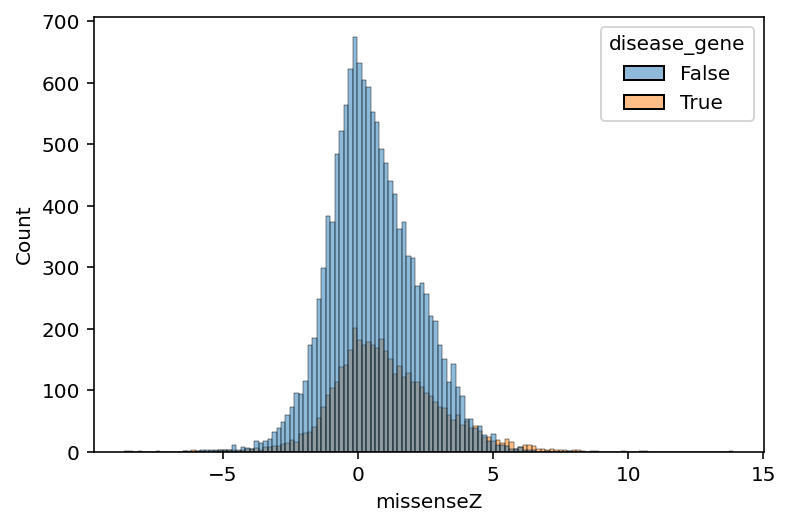

In [11]:
sns.histplot(data=bartha_dataset_df, x='missenseZ',hue='disease_gene')

<AxesSubplot:xlabel='missenseZ', ylabel='pLi'>

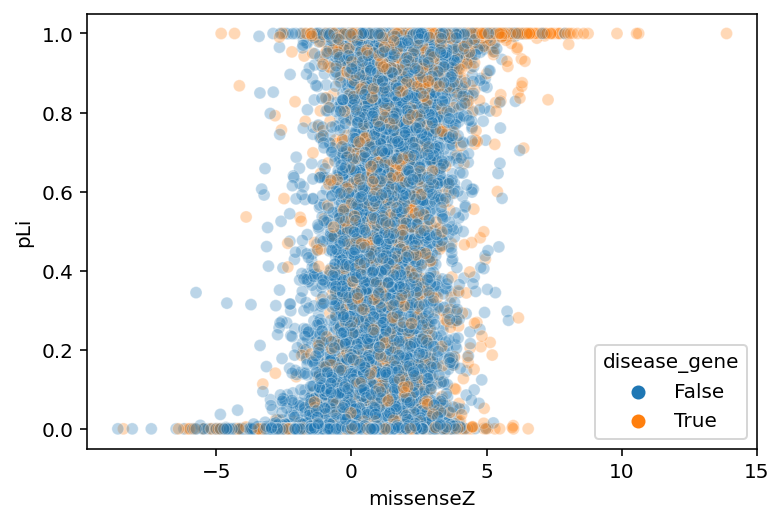

In [12]:
sns.scatterplot(data=bartha_dataset_df,  x='missenseZ',y='pLi',hue='disease_gene', alpha=0.3)

<AxesSubplot:xlabel='disease_gene', ylabel='missenseZ'>

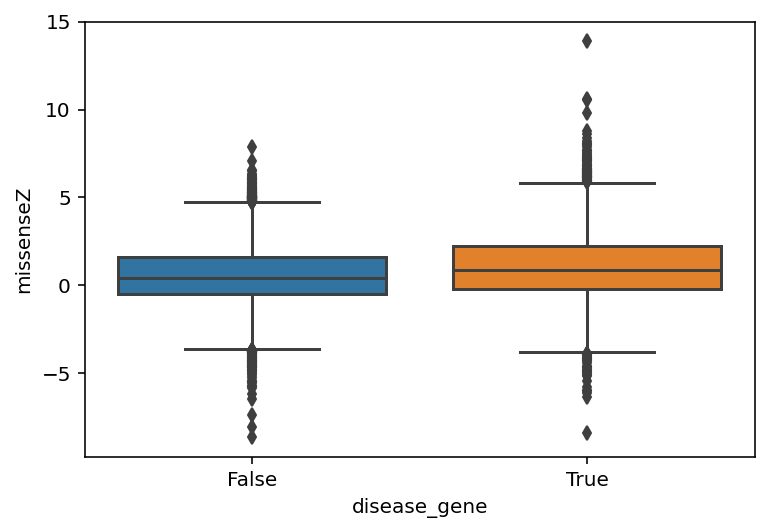

In [13]:
sns.boxplot(data=bartha_dataset_df, x='disease_gene',y='missenseZ')

<AxesSubplot:xlabel='pLi', ylabel='Count'>

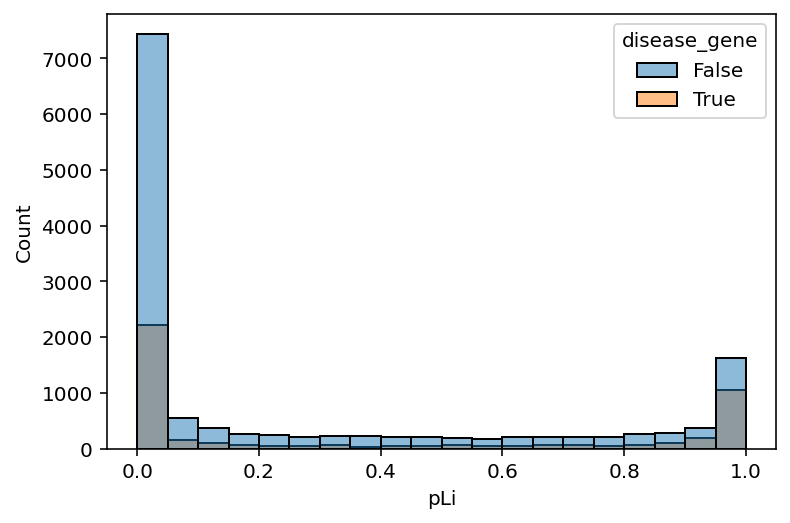

In [14]:
sns.histplot(data=bartha_dataset_df, x='pLi',hue='disease_gene')

<AxesSubplot:xlabel='disease_gene', ylabel='pLi'>

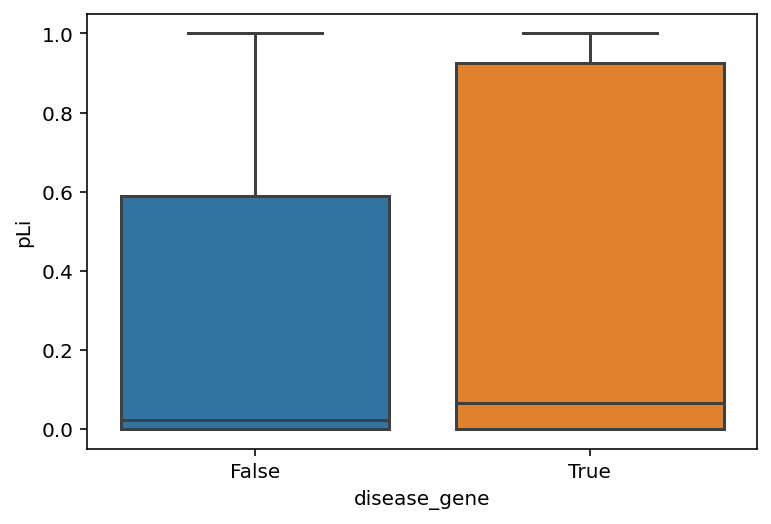

In [15]:
sns.boxplot(data=bartha_dataset_df, x='disease_gene',y='pLi')

#### Mode of inheritance

#### Co-complex membership

### XP data

In [16]:
allele_info_df = pd.read_csv('../../../database_management/20220228_Mikko_table_creation_and_updates/VUS_wt_allele_collection_entry_plates_allele_infos.csv', index_col=0)
#allele_info_df.query('orf_id == 7215.0 and mutation_id == 1976.0')
allele_info_d = {(orf_id,mutation_id):(nt_change,aa_change,'to_be_verified') for orf_id,mutation_id,nt_change,aa_change 
                 in zip(allele_info_df.orf_id, allele_info_df.mutation_id, allele_info_df.ensg, allele_info_df.nt_change)
                 if mutation_id == mutation_id
                }

allele_info_df.head()

,orf_id,symbol,node_type,mutation_id,entry_plate,entry_well,entry_well_id,ensg,nt_change,aa_change,chr,chr_pos_37,chr_pos_38
0,300,GALT,disease_wt,NaN,DisWTGDEh01,A01,1,NaN,NaN,NaN,NaN,NaN,NaN
1,12132,HCFC1,disease_wt,NaN,DisWTGDEh01,B01,2,NaN,NaN,NaN,NaN,NaN,NaN
2,7515,XRCC4,disease_wt,NaN,DisWTGDEh01,C01,3,NaN,NaN,NaN,NaN,NaN,NaN
3,10165,CRYBB1,disease_wt,NaN,DisWTGDEh01,D01,4,NaN,NaN,NaN,NaN,NaN,NaN
4,71642,CACNB4,disease_wt,NaN,DisWTGDEh01,E01,5,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
allele_collection = GetDFv2()

for i, (orf_id,nt_change,aa_change,symbol,ensg,entrez,rc4_mut_id,cegs_mut_id,vus_mut_id,rc4_plate,rc4_well,cegs_plate,cegs_well,vus_plate,vus_well,chr,chr_pos_37,chr_pos_38,cv_allele_id,hgmd_id,cv_clinical_significance,cv_phenotypes,cv_phenotype_ids,hgmd_clinical_significance,hgmd_phenotype,clinical_significance) in allele_collection.iterrows():
    for mut_id in [rc4_mut_id,cegs_mut_id,vus_mut_id]:
        if mut_id == mut_id:
            allele_info_d[orf_id,mut_id] = (nt_change,aa_change,clinical_significance)

#allele_collection.head()

In [18]:
orf_mapping = GetOrfMapping()
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))

In [19]:
ensg_to_symbol = dict(zip(orf_mapping.ensembl_gene_id, orf_mapping.symbol))

### Lit-BM

In [20]:
lit_bm_df = GetHI2018_paper(table='lit_17', col=('ensembl_gene_id_a' ,'ensembl_gene_id_b' ,'binary_low_throughput' ,'binary_not_y2h' ,'binary_method' ,'n_publications' ,'n_methods' ,'n_evidences' ,'category'))
lit_bm_df['symbol_a'] = lit_bm_df.ensembl_gene_id_a.map(ensg_to_symbol)
lit_bm_df['symbol_b'] = lit_bm_df.ensembl_gene_id_b.map(ensg_to_symbol)

lit_bm_df.head()


,ensembl_gene_id_a,ensembl_gene_id_b,binary_low_throughput,binary_not_y2h,binary_method,n_publications,n_methods,n_evidences,category,symbol_a,symbol_b
0,ENSG00000108469,ENSG00000181222,1,1,1,3,4,5,Lit-BM,RECQL5,POLR2A
1,ENSG00000078747,ENSG00000205726,1,1,1,1,2,2,Lit-BM,NaN,ITSN1
2,ENSG00000161011,ENSG00000188554,1,0,1,9,5,9,Lit-BM,SQSTM1,NBR1
3,ENSG00000078747,ENSG00000123405,1,1,1,2,4,4,Lit-BM,NaN,NFE2
4,ENSG00000173391,ENSG00000173391,1,1,1,2,4,4,Lit-BM,OLR1,OLR1


In [21]:
litbm_set = {tuple(sorted([a,b]))  for a,b in zip(lit_bm_df[lit_bm_df.category == 'Lit-BM'].symbol_a, 
                                                 lit_bm_df[lit_bm_df.category == 'Lit-BM'].symbol_b) if a == a and b == b}

litbs_set = {tuple(sorted([a,b]))  for a,b in zip(lit_bm_df[lit_bm_df.category == 'Lit-BS'].symbol_a, 
                                                 lit_bm_df[lit_bm_df.category == 'Lit-BS'].symbol_b) if a == a and b == b}


len(litbm_set), len(litbs_set)

(12291, 25449)

### pDEST DUAL

In [22]:
pdest_allele_wt_ratio_df = pd.read_csv('../../../pDEST_DUAL_stability_assay/processed_data_tables/allele_wt_ratio_table.tsv', sep='\t')
pdest_allele_wt_ratio_df['missenseZ'] = pdest_allele_wt_ratio_df.symbol.map(essential_missenseZ_d)
pdest_allele_wt_ratio_df['pLI'] = pdest_allele_wt_ratio_df.symbol.map(essential_pli_d)

pdest_allele_wt_ratio_df['missenseZ_essential'] = pdest_allele_wt_ratio_df.missenseZ.apply(lambda x: x >= 3)
pdest_allele_wt_ratio_df['pLI_essential'] = pdest_allele_wt_ratio_df.pLI.apply(lambda x: x >= 0.9)

pdest_allele_wt_ratio_df.head()

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,stability,experiment_id,missenseZ,pLI,missenseZ_essential,pLI_essential
0,55247.0,Ser162Gly,484A>G,other,-3.761045,-5.317992,-1.556948,2175,0,OAS1,-0.595613,no effect,"(55247.0, '484A>G')",-0.854583,0.001239,False,False
1,3020.0,Glu313Lys,937G>A,Pathogenic,-0.601091,-3.012488,-2.411397,1192,0,CHN1,-1.181620,destabilizing,"(3020.0, '937G>A')",0.819539,0.837424,False,False
2,3020.0,Pro252Ser,754C>T,Pathogenic,-0.601091,-2.850184,-2.249092,1192,0,CHN1,-1.070306,destabilizing,"(3020.0, '754C>T')",0.819539,0.837424,False,False
3,3020.0,Ala223Val,668C>T,Pathogenic,-0.601091,-2.903849,-2.302757,1192,0,CHN1,-1.107111,destabilizing,"(3020.0, '668C>T')",0.819539,0.837424,False,False
4,3020.0,Leu20Phe,60A>T,Pathogenic,-0.601091,-2.687816,-2.086725,1192,0,CHN1,-0.958950,no effect,"(3020.0, '60A>T')",0.819539,0.837424,False,False


In [141]:
#newer version of pdest assay
pdest_wt_normalized  = pd.read_csv('../../../vus_python_library/pdest_wt_normalized.tsv',sep='\t', index_col=0)

pdest_wt_normalized.sort_values(by='pla', inplace=True)

pdest_wt_normalized_d = {(orf_id,mut_id):(allele_wt_ratio,zscore,zcat) for i,(avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,orf_id,mut_id,node_type,nt_change,aa_change,clinical_significance,symbol,valid_well,z_pdest_empty,z_pdest_gfp,valid_gfp_mcherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat) in pdest_wt_normalized.iterrows()}

pdest_wt_normalized.head()

,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,orf_id,mut_id,node_type,nt_change,aa_change,clinical_significance,symbol,valid_well,z_pdest_empty,z_pdest_gfp,valid_gfp_mcherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat
7815640,2872.829775,4639.467329,1.012628,1,E02,"(1, 'E02')",10205,70497.0,3787.0,allele,74T>G,Leu25Arg,Pathogenic,AGXT,True,54.895461,2.401535,NaN,1.257684,0.805153,-0.746116,0
15554362,379.662852,3531.075133,0.182132,1,C07,"(1, 'C07')",11533,70497.0,3823.0,allele,466G>A,Gly156Arg,Pathogenic,AGXT,True,9.313307,-0.176322,NaN,1.257684,0.144816,-2.997118,-2
5129530,57.884976,2235.480245,0.046062,1,E11,"(1, 'E11')",1156,70497.0,3862.0,allele,806T>C,Leu269Pro,Pathogenic,AGXT,True,1.845019,-0.598685,NaN,1.257684,0.036624,-3.365928,-2
1003055,1176.015522,1660.219849,0.989055,1,A11,"(1, 'A11')",1469,70497.0,3856.0,allele,731T>C,Ile244Thr,Pathogenic,AGXT,True,53.601631,2.328364,NaN,1.257684,0.786410,-0.810010,0
5116835,519.145660,2608.676803,0.319231,1,B06,"(1, 'B06')",12695,70497.0,3813.0,allele,335C>A,Ala112Asp,Pathogenic,AGXT,True,16.838037,0.249232,NaN,1.257684,0.253824,-2.625521,-2


In [25]:
pdest_d = dict()

for orf_id,nt_change,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,stability in zip(pdest_allele_wt_ratio_df.orf_id, pdest_allele_wt_ratio_df.nt_change, pdest_allele_wt_ratio_df.wt_gfp_mcherry_ratio, pdest_allele_wt_ratio_df.allele_gfp_mcherry_ratio,pdest_allele_wt_ratio_df.stability):
    
    pdest_d[orf_id,'WT'] = (wt_gfp_mcherry_ratio,stability)
    pdest_d[orf_id,nt_change] = (allele_gfp_mcherry_ratio,stability)
        

In [26]:
pdest_allele_wt_ratio_df.experiment_id.nunique()

1080

In [27]:
pdest_allele_wt_ratio_df.orf_id.nunique()

108

<AxesSubplot:xlabel='missenseZ', ylabel='Count'>

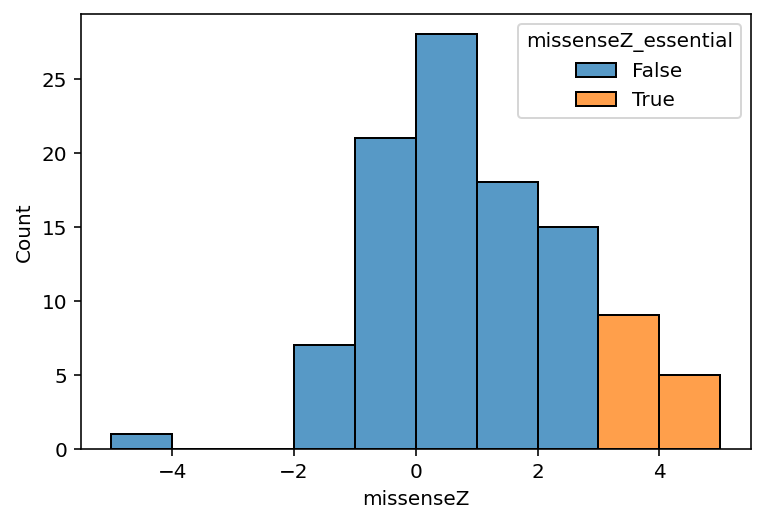

In [28]:
pdest_gene_df = pdest_allele_wt_ratio_df[['symbol','missenseZ','pLI','missenseZ_essential','pLI_essential']].drop_duplicates().copy()

sns.histplot(data=pdest_gene_df, x='missenseZ', hue='missenseZ_essential', multiple="stack", bins=10, binrange=(-5,5))

<AxesSubplot:xlabel='missenseZ', ylabel='Count'>

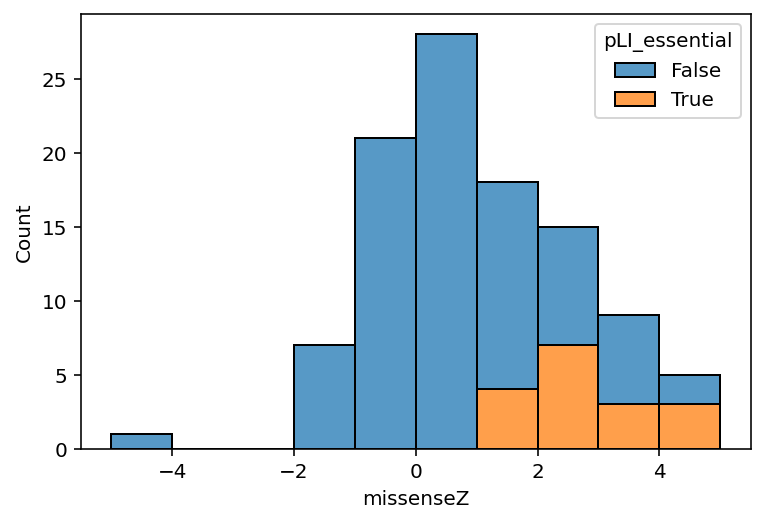

In [29]:
pdest_gene_df = pdest_allele_wt_ratio_df[['symbol','missenseZ','pLI','missenseZ_essential','pLI_essential']].drop_duplicates().copy()

sns.histplot(data=pdest_gene_df, x='missenseZ', hue='pLI_essential', multiple="stack", bins=10, binrange=(-5,5))

<AxesSubplot:xlabel='pLI', ylabel='Count'>

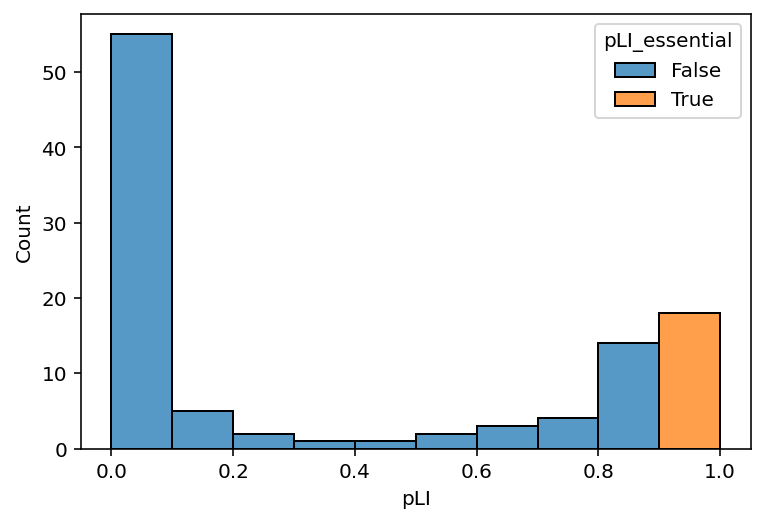

In [30]:
pdest_gene_df = pdest_allele_wt_ratio_df[['symbol','missenseZ','pLI','missenseZ_essential','pLI_essential']].drop_duplicates().copy()

sns.histplot(data=pdest_gene_df, x='pLI', hue='pLI_essential', multiple="stack", bins=10)

<AxesSubplot:xlabel='pLI', ylabel='Count'>

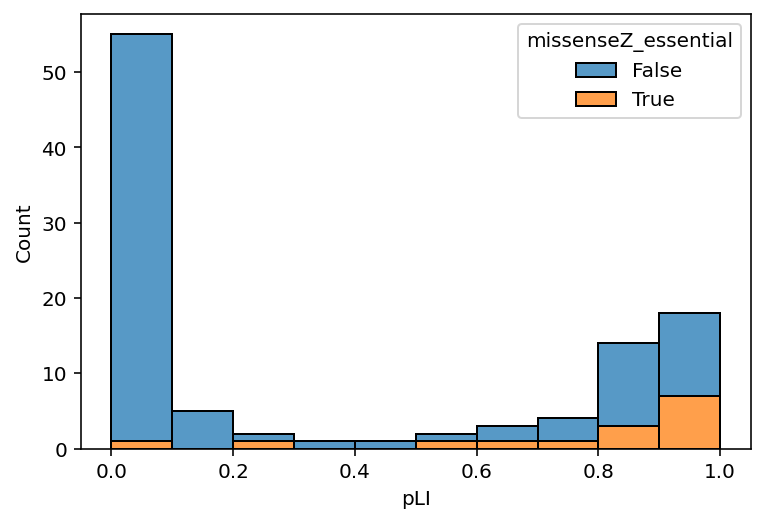

In [31]:
pdest_gene_df = pdest_allele_wt_ratio_df[['symbol','missenseZ','pLI','missenseZ_essential','pLI_essential']].drop_duplicates().copy()

sns.histplot(data=pdest_gene_df, x='pLI', hue='missenseZ_essential', multiple="stack", bins=10)

<AxesSubplot:xlabel='pLI', ylabel='Count'>

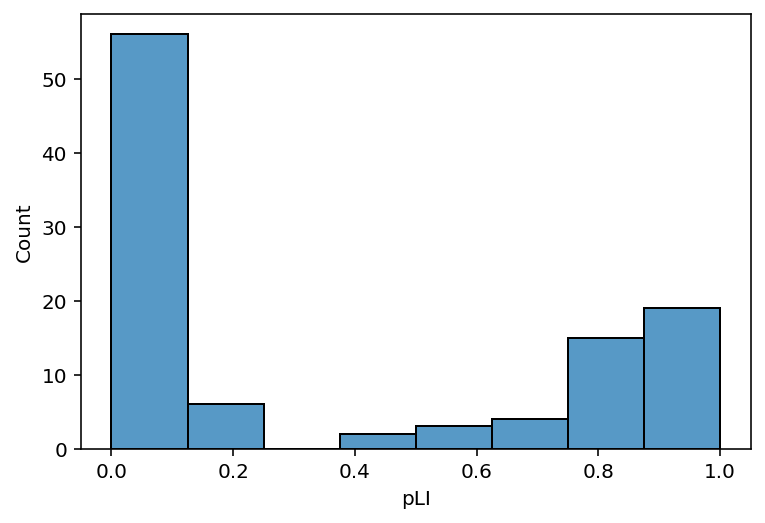

In [32]:
sns.histplot(data=pdest_gene_df, x='pLI')

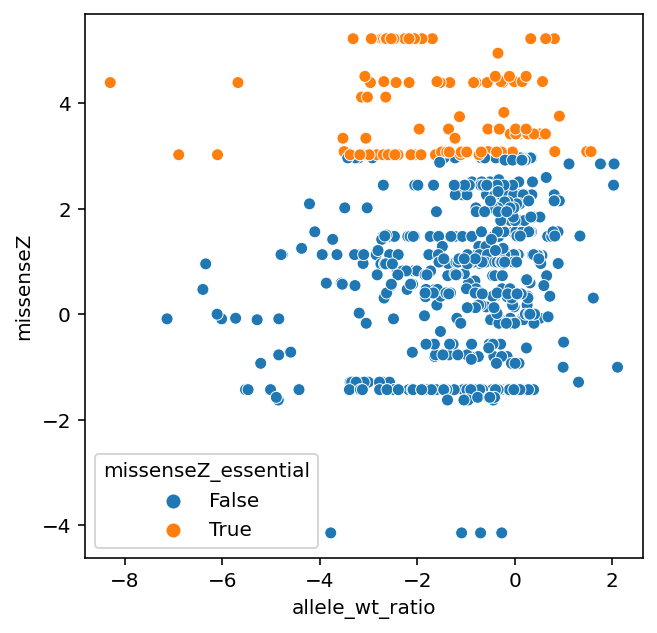

In [33]:
df = pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic' and ~missenseZ.isnull()")
data1 = df.allele_wt_ratio
data2 = df.missenseZ
 
#pearsonr = pearsonr(data1, data2)
#print(pearsonr)

plt.figure(figsize=(5,5))

sns.scatterplot(data=df, x='allele_wt_ratio', y='missenseZ', hue='missenseZ_essential')

plt.show()

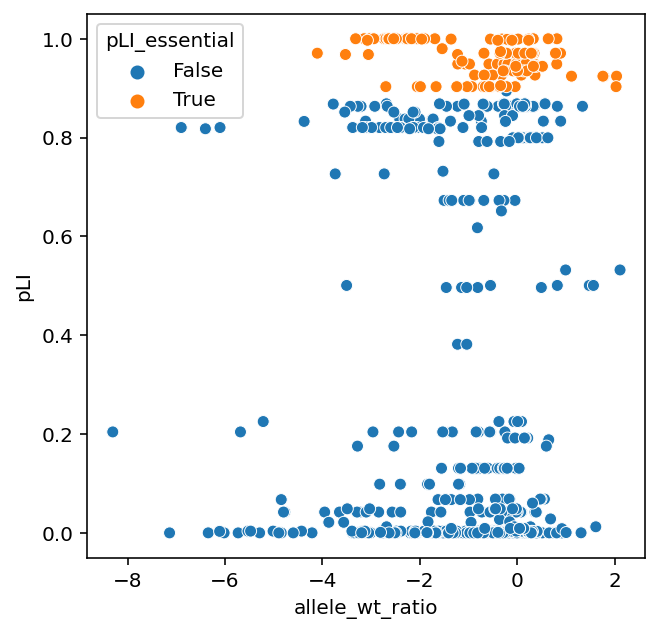

In [34]:
plt.figure(figsize=(5,5))

sns.scatterplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), x='allele_wt_ratio', y='pLI', hue='pLI_essential')

plt.show()

In [35]:
pdest_allele_wt_ratio_df.head()

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,stability,experiment_id,missenseZ,pLI,missenseZ_essential,pLI_essential
0,55247.0,Ser162Gly,484A>G,other,-3.761045,-5.317992,-1.556948,2175,0,OAS1,-0.595613,no effect,"(55247.0, '484A>G')",-0.854583,0.001239,False,False
1,3020.0,Glu313Lys,937G>A,Pathogenic,-0.601091,-3.012488,-2.411397,1192,0,CHN1,-1.181620,destabilizing,"(3020.0, '937G>A')",0.819539,0.837424,False,False
2,3020.0,Pro252Ser,754C>T,Pathogenic,-0.601091,-2.850184,-2.249092,1192,0,CHN1,-1.070306,destabilizing,"(3020.0, '754C>T')",0.819539,0.837424,False,False
3,3020.0,Ala223Val,668C>T,Pathogenic,-0.601091,-2.903849,-2.302757,1192,0,CHN1,-1.107111,destabilizing,"(3020.0, '668C>T')",0.819539,0.837424,False,False
4,3020.0,Leu20Phe,60A>T,Pathogenic,-0.601091,-2.687816,-2.086725,1192,0,CHN1,-0.958950,no effect,"(3020.0, '60A>T')",0.819539,0.837424,False,False


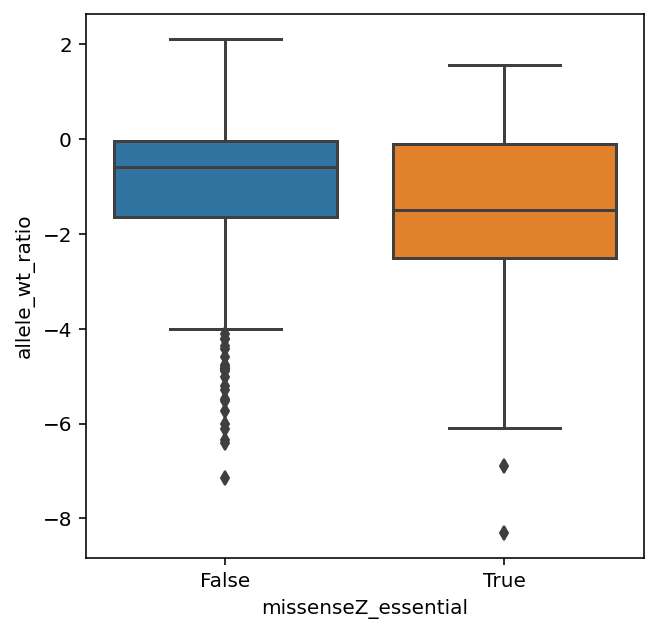

In [36]:
plt.figure(figsize=(5,5))

sns.boxplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), y='allele_wt_ratio', x='missenseZ_essential')

plt.show()

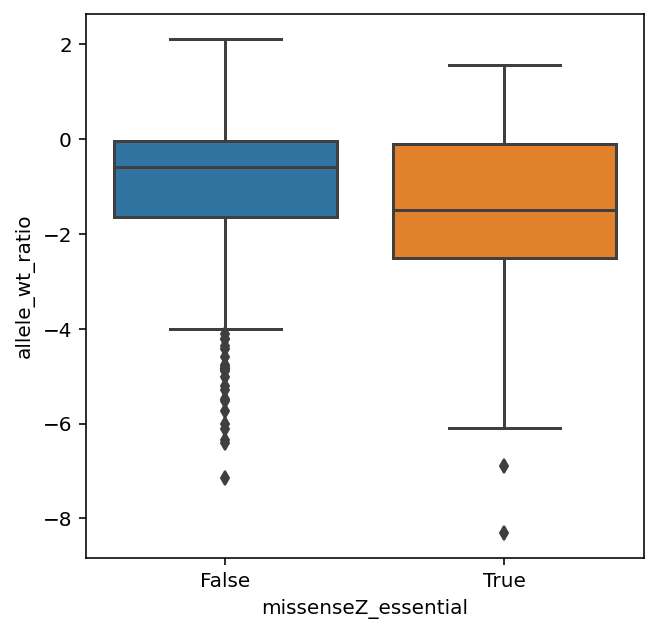

In [37]:
plt.figure(figsize=(5,5))

sns.boxplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), y='allele_wt_ratio', x='missenseZ_essential')

plt.show()

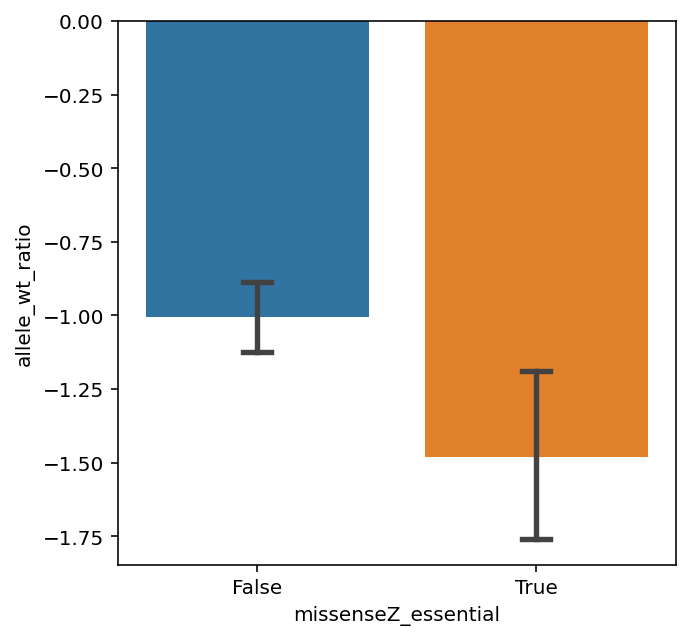

In [38]:
plt.figure(figsize=(5,5))

sns.barplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), y='allele_wt_ratio', x='missenseZ_essential', capsize=0.1)

plt.show()

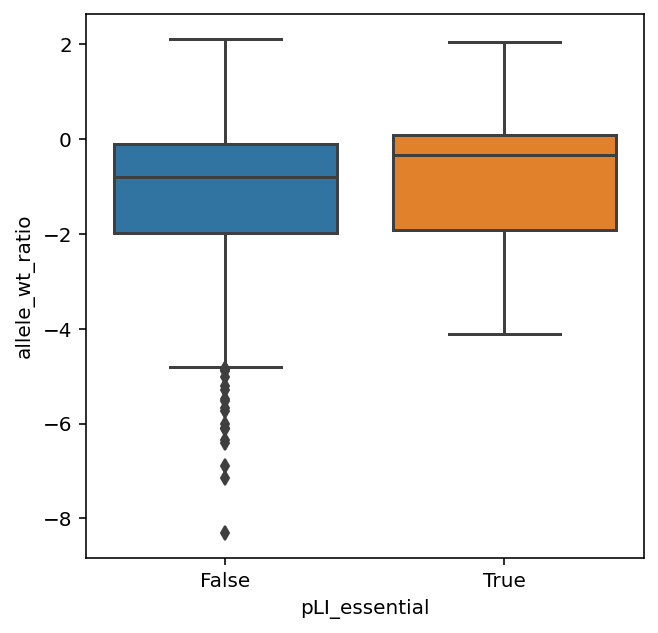

In [39]:
plt.figure(figsize=(5,5))

sns.boxplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), y='allele_wt_ratio', x='pLI_essential')

plt.show()

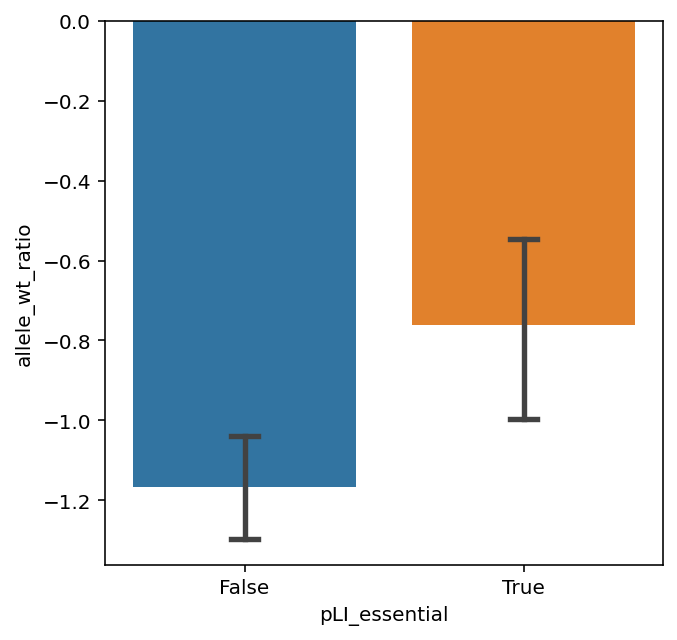

In [40]:
plt.figure(figsize=(5,5))

sns.barplot(data=pdest_allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'"), y='allele_wt_ratio', x='pLI_essential', capsize=0.1)

plt.show()

### N2H

#### mN2H

In [41]:
#pd.read_csv('../../mN2H_experiment/20210823_vus_apwt/mN2H_allele_edgotyping_raw_data.csv')

In [42]:
mN2H_df = pd.read_csv('/Users/georgescoppin/Downloads/mN2H_allele_edgotyping_raw_data.csv', index_col=0)

mN2H_df['NLR1'] = [xp/max(en1,en2) for xp,en1,en2 in zip(mN2H_df.N1N2_xp1, mN2H_df.empty_N1_xp1, mN2H_df.empty_N2_xp1)]
mN2H_df['NLR2'] = [xp/max(en1,en2) for xp,en1,en2 in zip(mN2H_df.N1N2_xp2, mN2H_df.empty_N1_xp2, mN2H_df.empty_N2_xp2)]

mN2H_df['avg_NLR'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) for nlr1, nlr2 in zip(mN2H_df.NLR1, mN2H_df.NLR2)]

mN2H_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR1,NLR2,avg_NLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,17.177984,17.647623,17.412804
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,4.007174,4.158825,4.082999
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,17.180294,13.591274,15.385784
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,0.386369,0.570607,0.478488
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,7.954820,10.921451,9.438135


In [43]:
mN2H_df[(mN2H_df.variant_id == 'RRS')&(mN2H_df.avg_NLR > 50)]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR1,NLR2,avg_NLR
147,2003,SLC6A1,6773,TM4SF4,0,RRS,2,G07,8.696898e+06,13671663.0,135747.333333,64191.666667,238657.333333,70065.666667,64.066803,57.285744,60.676274
402,3409,PBX2,3375,VILL,0,RRS,5,C04,7.253950e+05,1374189.0,12891.000000,1397.000000,26769.000000,3180.666667,56.271430,51.335089,53.803259
426,3341,CKB,8297,HBZ,0,RRS,5,C07,2.091960e+06,1886292.0,1888.000000,225.333333,2834.666667,481.000000,1108.029661,665.436971,886.733316


<AxesSubplot:ylabel='Frequency'>

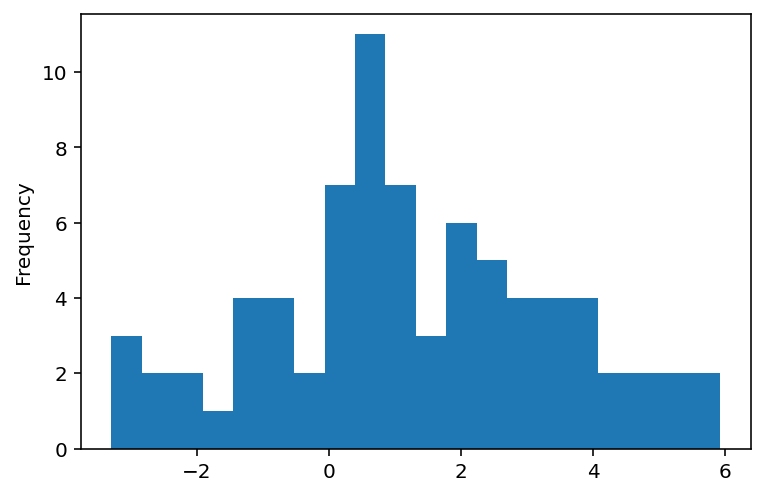

In [44]:
mN2H_df[(mN2H_df.variant_id == 'RRS')&(mN2H_df.avg_NLR < 80)].avg_NLR.apply(np.log2).plot.hist(bins=20)

<AxesSubplot:ylabel='Frequency'>

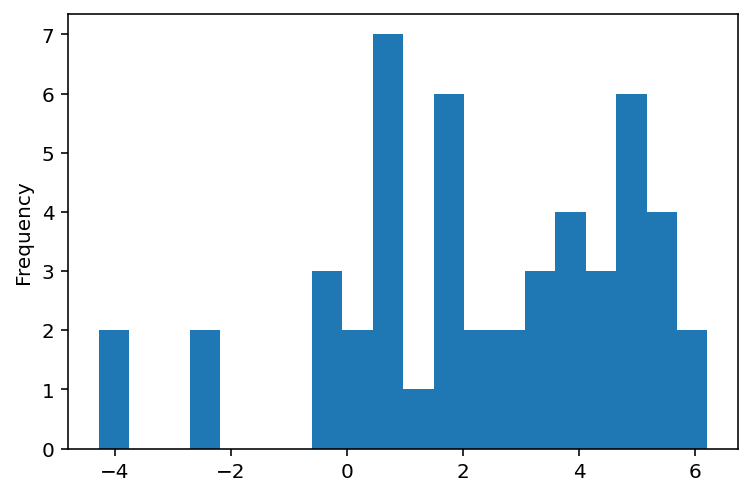

In [45]:
mN2H_df[(mN2H_df.variant_id == 'PRS')&(mN2H_df.avg_NLR < 80)].avg_NLR.apply(np.log2).plot.hist(bins=20)

In [46]:
(2.23 * np.std(mN2H_df[(mN2H_df.variant_id == 'RRS')&(mN2H_df.avg_NLR < 80)].avg_NLR)) + np.mean(mN2H_df[(mN2H_df.variant_id == 'RRS')&(mN2H_df.avg_NLR < 80)].avg_NLR)

32.71650111004827

In [50]:
mN2H_d = {(N2_orf_id,N2_mut_id,N1_orf_id):(N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR1,NLR2) for i,
          (N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR1,NLR2,avg_NLR)
          in mN2H_df.iterrows()
         }

In [49]:
mN2H_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR1,NLR2,avg_NLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,17.177984,17.647623,17.412804
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,4.007174,4.158825,4.082999
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,17.180294,13.591274,15.385784
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,0.386369,0.570607,0.478488
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,7.954820,10.921451,9.438135


#### yN2H

In [51]:
yN2H_df = pd.read_csv('../../../vus_python_library/yN2H_APWT_raw_score.csv', index_col=0)
yN2H_df['avg_NLR'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) if (nlr1 == nlr1 and nlr2 == nlr2) else np.nan for nlr1, nlr2 in zip(yN2H_df.NLR1, yN2H_df.NLR2)]


yN2H_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,avg_NLR
0,71963,MBD3L1,2713,MLH1,981.0,4,H05,yN2Hapwt,allele,96,82,False,False,62,199,76,144,0.482412,0.569444,0.525928
1,11452,WASHC1,4723,TPM1,201730.0,4,G05,yN2Hapwt,allele,336,103,False,False,117,137,124,110,2.452555,0.830645,1.641600
2,361,GRAMD2B,3438,TMEM43,0.0,4,F05,yN2Hapwt,wt,6558,2033,False,False,144,1174,220,1264,5.586031,1.608386,3.597208
3,71892,TH,71892,TH,4005.0,4,E05,yN2Hapwt,allele,1092,254,False,False,227,144,302,213,4.810573,0.841060,2.825816
4,2500,ZNF212,2713,MLH1,0.0,4,D05,yN2Hapwt,wt,124,82,False,False,165,185,199,117,0.670270,0.412060,0.541165


In [52]:
detection_threshold = (2.23 * np.std(yN2H_df[(yN2H_df.variant_id == 'RRS')].avg_NLR)) + np.mean(yN2H_df[(yN2H_df.variant_id == 'RRS')].avg_NLR)
detection_threshold


1.3434114096307597

In [53]:
yN2H_df[(yN2H_df.variant_id == 'RRS')&(yN2H_df.avg_NLR > 1.35)]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,avg_NLR
2537,3789,CANX,9931,ARHGEF15,NaN,24,A07,yN2Hapwt,RRS,151,584,False,False,124,144,124,261,1.048611,2.237548,1.643080
3147,2003,SLC6A1,6773,TM4SF4,NaN,35,D03,yN2Hapwt,RRS,158,288,False,False,151,89,103,117,1.046358,2.461538,1.753948


In [54]:
len(yN2H_df[(yN2H_df.variant_id == 'PRS')&(yN2H_df.avg_NLR > 1.35)])

16

In [55]:
yN2H_df.variant_id.value_counts()

allele    1786
wt         239
RRS         78
PRS         60
Name: variant_id, dtype: int64

In [57]:
yN2H_d = {(db_orf_id,db_mut_id,ad_orf_id):(yN2H_score_rep1,yN2H_score_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2) for i,
         (ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,avg_nlr)
         in yN2H_df.iterrows()
         }

### Nano Y2H

In [58]:
hsPRSRRSv2_df = pd.read_csv('processed_data/hsPRSRRSv2.csv')
hsRRSv2_df = pd.read_csv('processed_data/hsRRSv2_for_setting_detection_threshold.csv')
nanoY2H_dataset_df = pd.read_csv('processed_data/nanoY2H_processed_df.csv')
nanoY2H_dataset_df['nt_change'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][0] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nanoY2H_dataset_df.db_orf_id, nanoY2H_dataset_df.db_mut_id, nanoY2H_dataset_df.retest_type)]
nanoY2H_dataset_df['aa_change'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][1] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nanoY2H_dataset_df.db_orf_id, nanoY2H_dataset_df.db_mut_id, nanoY2H_dataset_df.retest_type)]
nanoY2H_dataset_df['clinical_significance'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][2] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nanoY2H_dataset_df.db_orf_id, nanoY2H_dataset_df.db_mut_id, nanoY2H_dataset_df.retest_type)]
nanoY2H_dataset_df['mut_pos'] = nanoY2H_dataset_df.aa_change.apply(lambda x: 0 if x == 'WT' else int(x[3:-3]))
#nanoY2H_dataset_df['qY2H'] = [qy2h_d[(db,ad,mut)] if (db,ad,mut) in qy2h_d else np.nan for ad,db,mut in zip(nanoY2H_dataset_df.ad_orf_id, nanoY2H_dataset_df.db_orf_id, nanoY2H_dataset_df.db_mut_id)]
#nanoY2H_dataset_df['qY2H_score_norm'] = nanoY2H_dataset_df.qY2H.apply( lambda x: x if x != x else x[3])
#nanoY2H_dataset_df['']

nanoY2H_dataset_d = {(db_orf_id,db_mut_id,ad_orf_id):(NLR,detected) for db_orf_id,db_mut_id,ad_orf_id,NLR,detected in zip(nanoY2H_dataset_df.db_orf_id, nanoY2H_dataset_df.db_mut_id, nanoY2H_dataset_df.ad_orf_id, nanoY2H_dataset_df.NLR, nanoY2H_dataset_df.detected)}

nanoY2H_dataset_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd,nt_change,aa_change,clinical_significance,mut_pos
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,12671,4.102811,False,False,18984.0,-0.583254,False,-8.309804,WT,WT,WT,0
1,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,23360,4.368473,False,False,27489.0,-0.234814,False,-8.309804,WT,WT,WT,0
2,54387.0,FLT3LG,0.0,54530.0,FLT3,1.0,kd,11682,4.067517,False,False,16394.0,-0.488881,False,-7.397940,WT,WT,WT,0
3,13530.0,LCN2,0.0,55203.0,FN1,1.0,kd,12760,4.105851,False,False,10219.0,0.320374,False,-8.238824,WT,WT,WT,0
4,55203.0,FN1,0.0,13530.0,LCN2,1.0,kd,22948,4.360745,False,False,23648.0,-0.043350,False,-8.238824,WT,WT,WT,0


In [59]:
len(nanoY2H_dataset_df[(nanoY2H_dataset_df.nt_change == 'WT')&(nanoY2H_dataset_df.retest_type != 'kd')])

584

In [60]:
nanoY2H_dataset_df[(nanoY2H_dataset_df.nt_change == 'WT')&(nanoY2H_dataset_df.retest_type != 'kd')].detected.sum()

199

In [61]:
(~nanoY2H_dataset_df.detected).sum()

3767

In [62]:
len(nanoY2H_dataset_df[(nanoY2H_dataset_df.nt_change == 'WT')&(nanoY2H_dataset_df.detected)])

215

In [63]:
nanoY2H_dataset_df.retest_type.value_counts()

nY2H_APWT    4569
kd            325
Name: retest_type, dtype: int64

In [64]:
nanoY2H_dataset_df[nanoY2H_dataset_df.retest_type == 'nY2H_APWT'].db_symbol.nunique()

119

In [65]:
len(nanoY2H_dataset_df)

4894

In [66]:
pd.Series((zip(nanoY2H_dataset_df[nanoY2H_dataset_df.db_mut_id!=0].db_orf_id, nanoY2H_dataset_df[nanoY2H_dataset_df.db_mut_id!=0].db_mut_id))).nunique()

771

In [67]:
nanoY2H_dataset_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd,nt_change,aa_change,clinical_significance,mut_pos
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,12671,4.102811,False,False,18984.0,-0.583254,False,-8.309804,WT,WT,WT,0
1,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,23360,4.368473,False,False,27489.0,-0.234814,False,-8.309804,WT,WT,WT,0
2,54387.0,FLT3LG,0.0,54530.0,FLT3,1.0,kd,11682,4.067517,False,False,16394.0,-0.488881,False,-7.397940,WT,WT,WT,0
3,13530.0,LCN2,0.0,55203.0,FN1,1.0,kd,12760,4.105851,False,False,10219.0,0.320374,False,-8.238824,WT,WT,WT,0
4,55203.0,FN1,0.0,13530.0,LCN2,1.0,kd,22948,4.360745,False,False,23648.0,-0.043350,False,-8.238824,WT,WT,WT,0


In [68]:

df = nanoY2H_dataset_df[(nanoY2H_dataset_df.db_mut_id!=0)]

pd.Series((zip(nanoY2H_dataset_df[nanoY2H_dataset_df.db_mut_id!=0].db_orf_id, nanoY2H_dataset_df[nanoY2H_dataset_df.db_mut_id!=0].db_mut_id))).nunique()



771

In [69]:
#df = nanoY2H_dataset_df[(~nanoY2H_dataset_df.qY2H.isnull())&(nanoY2H_dataset_df.db_mut_id == 0)]

#sns.boxplot(data=df[df.qY2H_score_norm.isin([0,0.2,0.4,0.6,0.8,1])], x='qY2H_score_norm', y='NLR');

In [70]:
nanoY2H_dataset_df.retest_type.value_counts()

nY2H_APWT    4569
kd            325
Name: retest_type, dtype: int64

In [71]:
nanoY2H_dataset_df.query("db_mut_id == 0 and retest_type == 'nY2H_APWT'")
wt_d = {db_orf_id:(nlr,) for db_orf_id,nlr,rlu,rlu_ctrl in zip(nanoY2H_dataset_df.db_orf_id,nanoY2H_dataset_df.NLR,nanoY2H_dataset_df.RLU,nanoY2H_dataset_df.RLU_ctrl)}

nano_allele_df = nanoY2H_dataset_df.query("db_mut_id > 0 and retest_type == 'nY2H_APWT'").copy()
nano_allele_df.drop(columns=['Kd'],inplace=True)

# nano_allele_df['nt_change'] = ['WT' if retest_type == 'wt' else allele_info_d[db_orf_id,db_mut_id][0] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nano_allele_df.db_orf_id, nano_allele_df.db_mut_id, nano_allele_df.retest_type)]
# nano_allele_df['aa_change'] = ['WT' if retest_type == 'wt' else allele_info_d[db_orf_id,db_mut_id][1] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nano_allele_df.db_orf_id, nano_allele_df.db_mut_id, nano_allele_df.retest_type)]
# nano_allele_df['clinical_significance'] = ['WT' if retest_type == 'wt' else allele_info_d[db_orf_id,db_mut_id][2] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id,retest_type in zip(nano_allele_df.db_orf_id, nano_allele_df.db_mut_id, nano_allele_df.retest_type)]
#nano_allele_df['qY2H'] = nano_allele_df.qY2H.apply(lambda x: x[-1] if x == x else np.nan)
nano_allele_df['wt_NLR'] = nano_allele_df.db_orf_id.map(wt_d).apply(lambda x: x[0])
nano_allele_df['wt_detected'] = nano_allele_df.wt_NLR.apply(lambda x: x >= 1.757)
#nano_allele_df['wt_qY2H'] = nano_allele_df.db_orf_id.map(wt_d).apply(lambda x: x[1])
#nano_allele_df['qY2H_ratio'] = nano_allele_df.qY2H / nano_allele_df.wt_qY2H
nano_allele_df['nanoY2H_ratio'] = np.log2(nano_allele_df.NLR / nano_allele_df.wt_NLR)
nano_allele_df.head()

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/pandas/core/arraylike.py:397: RuntimeWarning: invalid value encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,nt_change,aa_change,clinical_significance,mut_pos,wt_NLR,wt_detected,nanoY2H_ratio
325,11805.0,SMAD3,2134.0,71704.0,SMURF2,1.0,nY2H_APWT,238037,5.376644,False,False,16380.0,3.861179,True,508A>G,Ile170Val,Benign,170,0.746133,False,2.371537
326,11805.0,SMAD3,2145.0,71704.0,SMURF2,1.0,nY2H_APWT,198593,5.297964,False,False,26273.0,2.918162,True,772G>C,Asp258His,Conflicting,258,0.746133,False,1.967556
327,11805.0,SMAD3,2173.0,71704.0,SMURF2,1.0,nY2H_APWT,758081,5.879716,False,False,48924.0,3.953738,True,1117C>T,Arg373Cys,Conflicting,373,0.746133,False,2.405713
328,11805.0,SMAD3,2117.0,71704.0,SMURF2,1.0,nY2H_APWT,407918,5.610573,False,False,48497.0,3.072312,True,260T>C,Ile87Thr,VUS,87,0.746133,False,2.041821
329,11805.0,SMAD3,203607.0,71704.0,SMURF2,1.0,nY2H_APWT,261063,5.416745,False,False,66868.0,1.965010,True,788C>T,Pro263Leu,VUS,263,0.746133,False,1.397033


In [72]:
len(nano_allele_df[nano_allele_df.wt_detected])

772

In [73]:
len(nano_allele_df)

3985

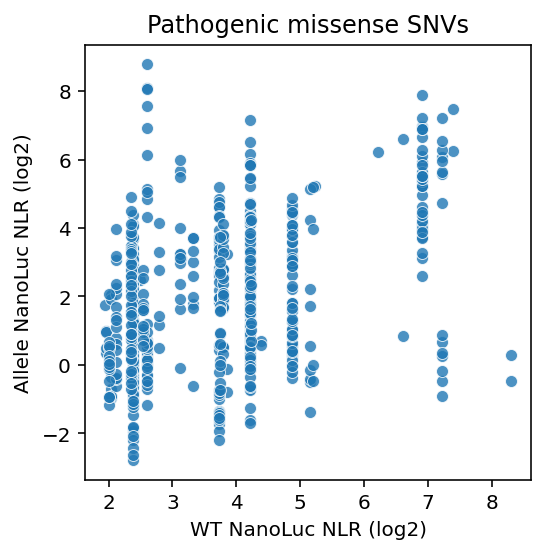

In [74]:
#stability_color_d = {'Destabilizing':'red','No effect':'Lightgrey','Stabilizing':'lightblue'}
plt.figure(figsize=(4,4))

sns.scatterplot(data=nano_allele_df.query("wt_detected and clinical_significance == 'Pathogenic'"), 
                x='wt_NLR', 
                y='NLR',
                #hue='Stability impact',
                alpha=0.8,
                #palette=stability_color_d
               )
plt.title('Pathogenic missense SNVs')
#plt.xlim(-8,3)
#plt.ylim(-8,3)
plt.xlabel('WT NanoLuc NLR (log2)')
plt.ylabel('Allele NanoLuc NLR (log2)')

plt.show()

In [75]:
len(nano_allele_df.query("wt_detected and clinical_significance == 'Pathogenic'"))

640

In [76]:
nano_allele_df.query("wt_detected and clinical_significance == 'Pathogenic'").db_mut_id.nunique()

142

In [77]:
nano_allele_df.query("wt_detected and clinical_significance == 'Benign'").db_mut_id.nunique()

1

In [78]:
nano_allele_df.query("wt_detected and clinical_significance == 'Benign'")

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,nt_change,aa_change,clinical_significance,mut_pos,wt_NLR,wt_detected,nanoY2H_ratio
2797,5066.0,BAG3,201832.0,70073.0,PLA2G10,2.0,nY2H_APWT,28396,4.453257,False,False,6483.0,2.130954,True,1138C>T,Pro380Ser,Benign,380,2.605365,True,-0.289986
2803,5066.0,BAG3,201832.0,208.0,ARRDC3,1.0,nY2H_APWT,36930,4.567379,False,False,36016.0,0.036155,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,-6.171134
2809,5066.0,BAG3,201832.0,4759.0,VPS37B,1.0,nY2H_APWT,30464,4.483787,False,False,36016.0,-0.241533,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,NaN
2815,5066.0,BAG3,201832.0,9625.0,MAGED1,1.0,nY2H_APWT,47191,4.673859,False,False,36016.0,0.389874,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,-2.740406
2821,5066.0,BAG3,201832.0,3907.0,TRIP6,1.0,nY2H_APWT,40951,4.612265,False,False,36016.0,0.185261,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,-3.813857
2827,5066.0,BAG3,201832.0,13662.0,CYSRT1,1.0,nY2H_APWT,48126,4.682380,False,False,36016.0,0.418179,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,-2.639294
2833,5066.0,BAG3,201832.0,3598.0,DAZAP2,1.0,nY2H_APWT,33151,4.520497,False,False,36016.0,-0.119586,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,NaN
2839,5066.0,BAG3,201832.0,3048.0,PDE9A,1.0,nY2H_APWT,3730560,6.571774,False,False,36016.0,6.694610,True,1138C>T,Pro380Ser,Benign,380,2.605365,True,1.361515
2845,5066.0,BAG3,201832.0,4066.0,HSPB8,1.0,nY2H_APWT,9063336,6.957288,False,False,36016.0,7.975260,True,1138C>T,Pro380Ser,Benign,380,2.605365,True,1.614046
2851,5066.0,BAG3,201832.0,5143.0,MDFI,1.0,nY2H_APWT,54547,4.736771,False,False,36016.0,0.598862,False,1138C>T,Pro380Ser,Benign,380,2.605365,True,-2.121190


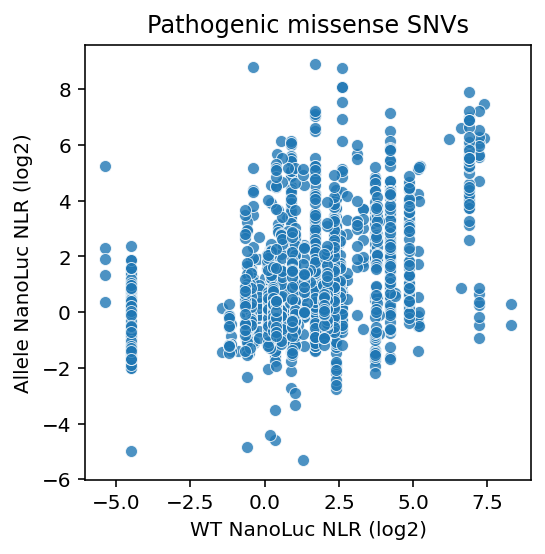

In [79]:


#stability_color_d = {'Destabilizing':'red','No effect':'Lightgrey','Stabilizing':'lightblue'}
plt.figure(figsize=(4,4))

sns.scatterplot(data=nano_allele_df.query("clinical_significance == 'Pathogenic'"), 
                x='wt_NLR', 
                y='NLR',
                #hue='Stability impact',
                alpha=0.8,
                #palette=stability_color_d
               )
plt.title('Pathogenic missense SNVs')
#plt.xlim(-8,3)
#plt.ylim(-8,3)
plt.xlabel('WT NanoLuc NLR (log2)')
plt.ylabel('Allele NanoLuc NLR (log2)')

plt.show()

<AxesSubplot:ylabel='Frequency'>

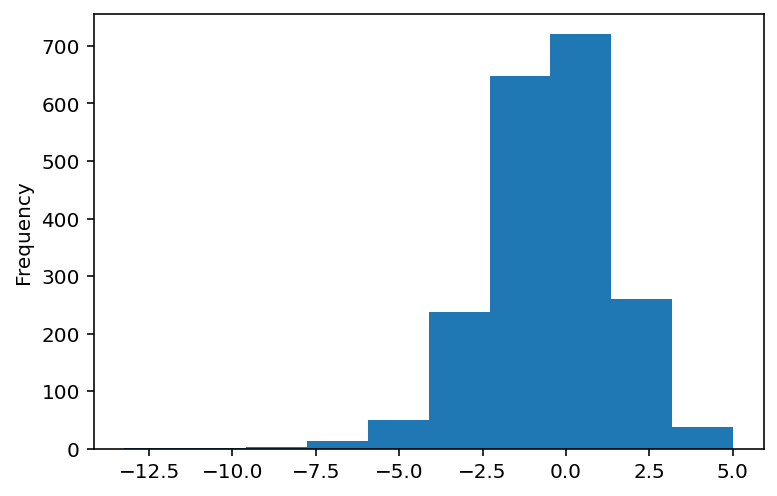

In [80]:
nano_allele_df.nanoY2H_ratio.plot.hist()

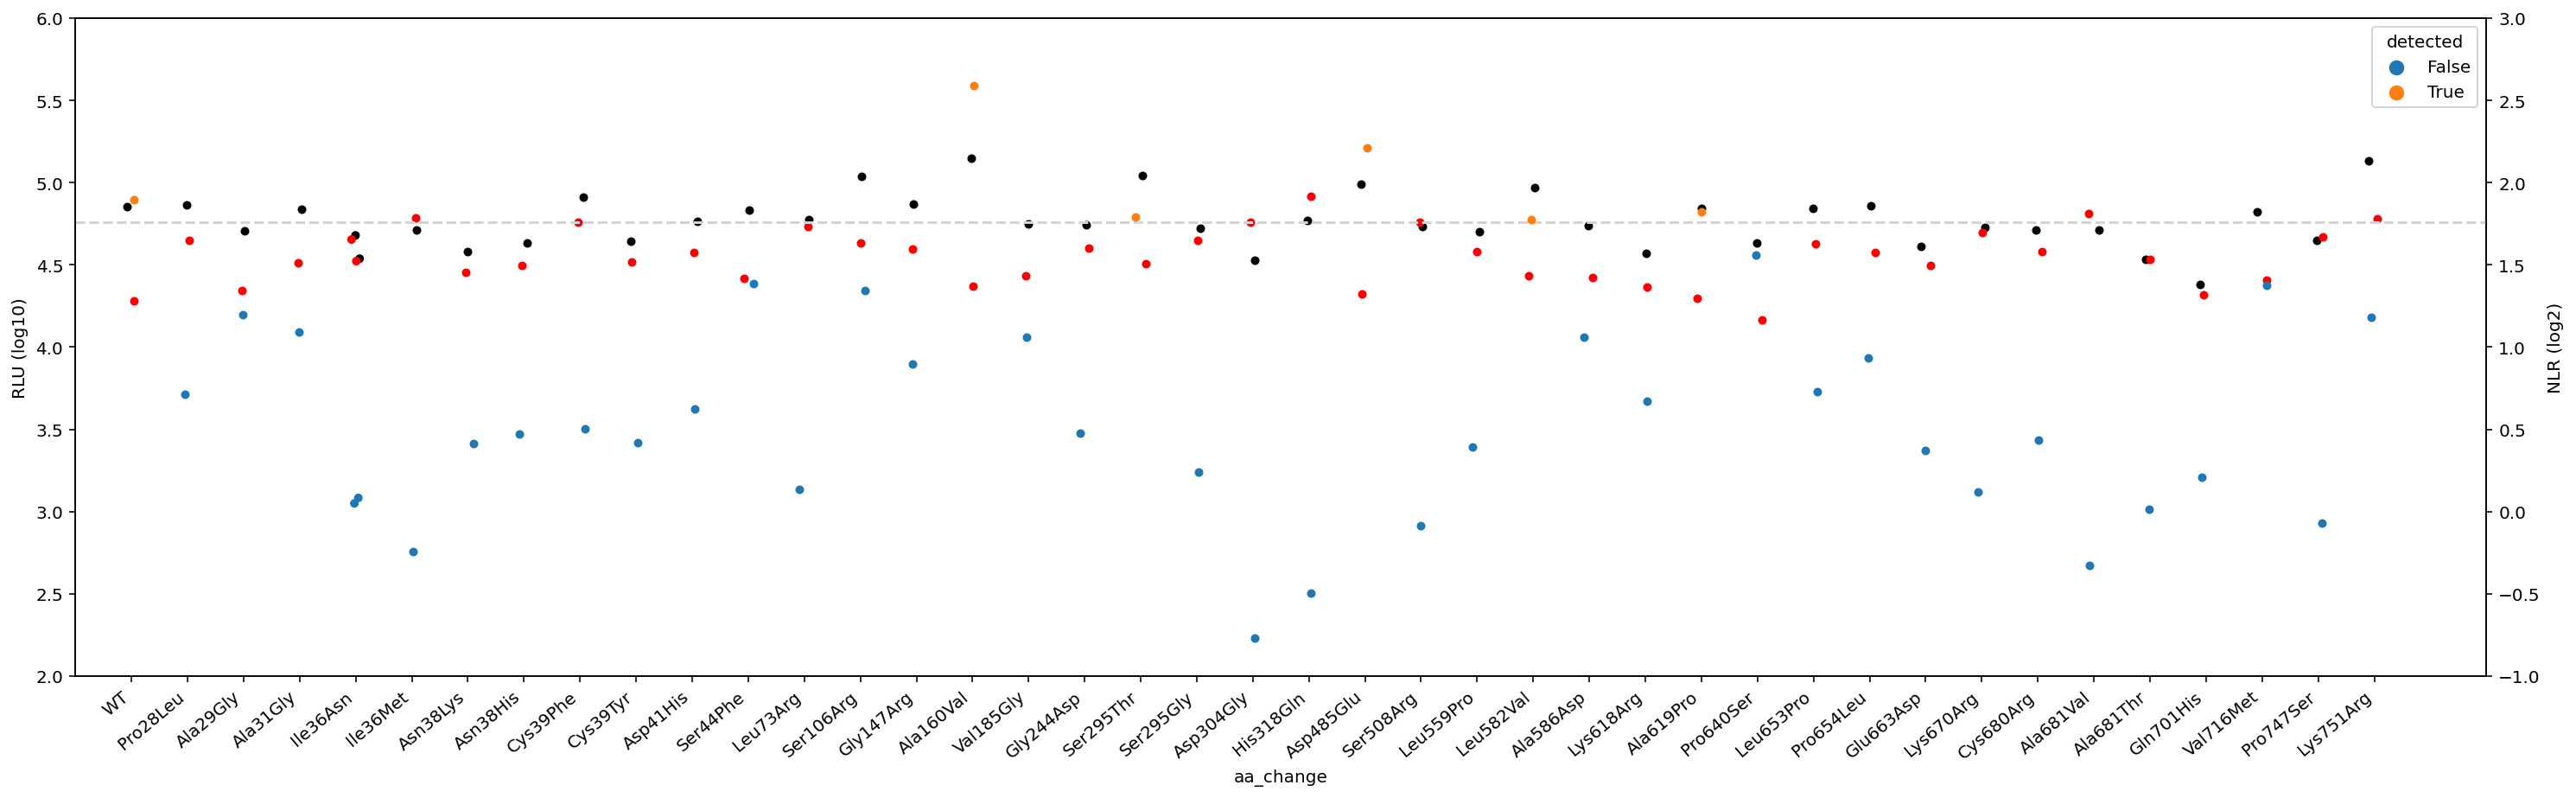

In [81]:
df = nanoY2H_dataset_df.query("retest_type=='nY2H_APWT' and db_symbol == 'MLH1' and ad_symbol == 'MBD4'").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)
fig, ax1 = plt.subplots(figsize=(25,7))

ax1.set_ylim(2,6)
ax2 = ax1.twinx()
ax2.set_ylim(-1,3)

g = sns.stripplot(data=df, y='RLU_log10',x='aa_change', color='black', ax=ax1)
g = sns.stripplot(data=df, y=df.RLU_ctrl.apply(np.log10),x='aa_change', color='red', ax=ax1)
g = sns.stripplot(data=df, y='NLR',x='aa_change', ax=ax2, hue='detected')

ax1.set_ylabel('RLU (log10)')
ax2.set_ylabel('NLR (log2)')

#ax1.hlines(xmin=-1,xmax=len(df),y=2.85, linestyle='--', color='lightgrey')
ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey')
ax1.set_xlim(-1,len(df))

ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')

#plt.ylim(2,6)
plt.show()

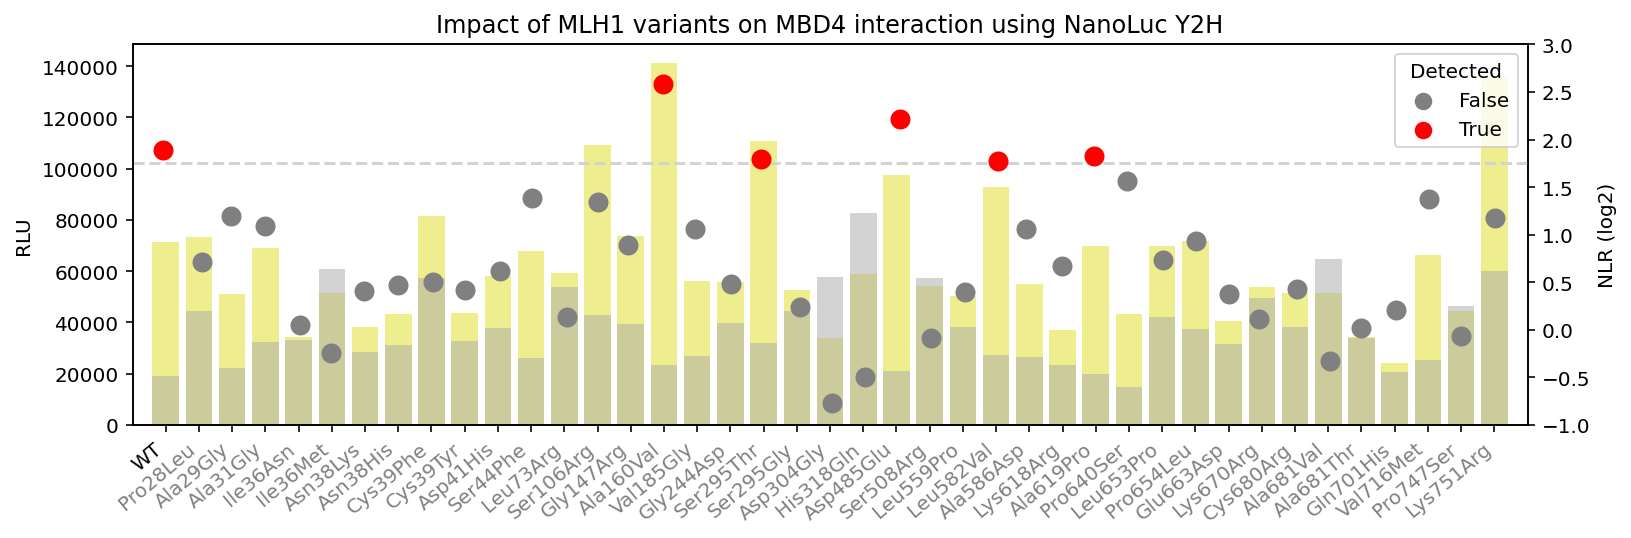

In [82]:
df = nanoY2H_dataset_df.query("retest_type=='nY2H_APWT' and db_symbol == 'MLH1' and ad_symbol == 'MBD4' and db_mut_id != 461.0").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)
df.rename(columns={'detected':'Detected'}, inplace=True)

#mut_l = ['WT', 'Pro28Leu', 'Ala29Gly', 'Ala31Gly', 'Ile36Asn', 'Ile36Met', 'Asn38Lys', 'Asn38His', 'Cys39Tyr', 'Cys39Phe', 'Asp41His', 'Leu73Arg', 'Ala160Val', 'Val185Gly', 'Ser295Thr', 'Ser295Gly', 'Asp304Gly', 'His318Gln', 'Leu559Pro', 'Leu582Val', 'Lys618Arg', 'Ala619Pro', 'Pro654Leu', 'Glu663Asp', 'Cys680Arg', 'Ala681Val', 'Ala681Thr', 'Gln701His', 'Val716Met', 'Pro747Ser', 'Lys751Arg']
#df=df[df.aa_change.isin(mut_l)]

def colorticks(event=None):
    locs, labels = plt.xticks()
    print(locs, labels)
    cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
    colors = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
    for k, v in colors.items():
        idxs = np.where(locs == k)[0]
        for pos in idxs:
            labels[pos].set_color(v)

fig, ax1 = plt.subplots(figsize=(12.5,3.5))

ax1.set_title(f'Impact of MLH1 variants on MBD4 interaction using NanoLuc Y2H')
#ax1.set_ylim(0,5.5)
ax2 = ax1.twinx()
ax2.set_ylim(-1,3)

g = sns.barplot(data=df, y='RLU',x='aa_change', color='yellow', ax=ax1, alpha=0.5)
g = sns.barplot(data=df, y=df.RLU_ctrl,x='aa_change', color='darkgrey', ax=ax1, alpha=0.5)
g = sns.stripplot(data=df, y='NLR',x='aa_change', ax=ax2, hue='Detected', size=10, palette={True:'r', False:'grey'})
#g = sns.stripplot(data=df, y='NLR',x='aa_change', ax=ax2, hue='Detected', size=10, palette={True:'b', False:'b'})



ax1.set_ylabel('RLU')
ax2.set_ylabel('NLR (log2)')

#ax1.hlines(xmin=-1,xmax=len(df),y=2.85, linestyle='--', color='lightgrey')
ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey')
ax1.set_xlim(-1,len(df))

ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
ax1.set_xlabel('')

cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
for xtick in ax1.get_xticklabels():
    xtick.set_color(colors_d[xtick.get_text()])
    
#plt.legend('')

plt.savefig('figures/NanoLuc_Y2H_MLH1_MBD4.png', bbox_inches='tight', dpi=300)
plt.show()

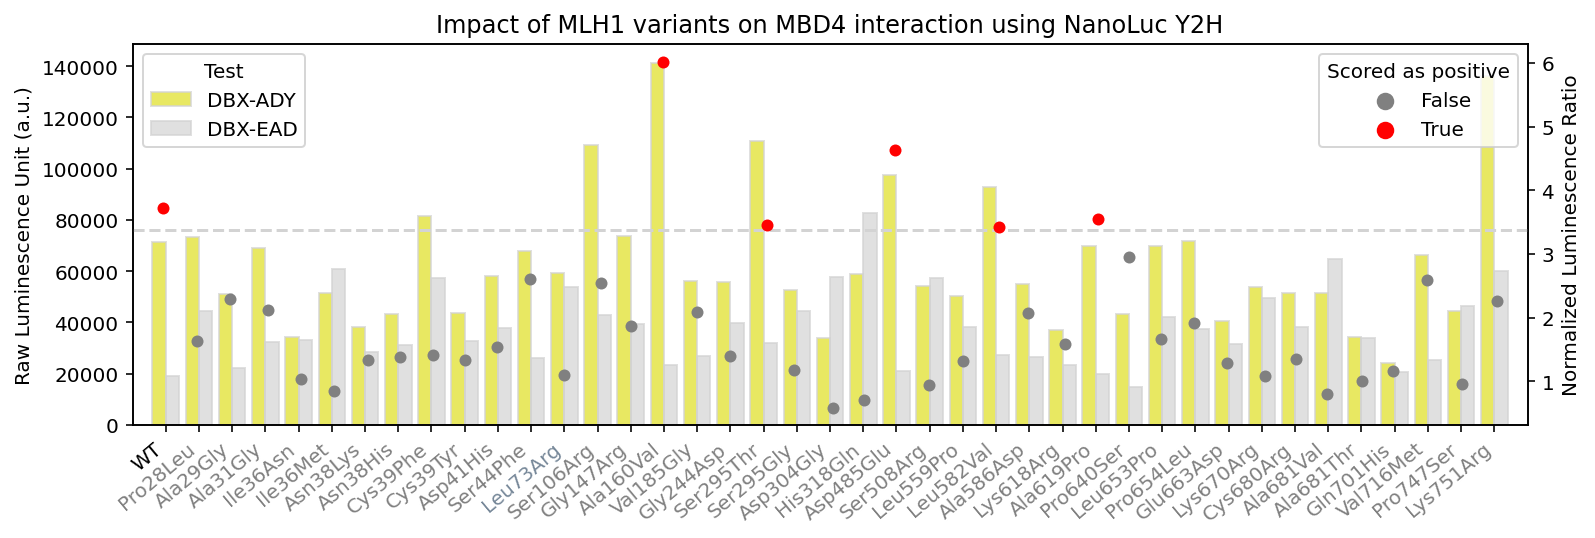

In [83]:
df = nanoY2H_dataset_df.query("retest_type=='nY2H_APWT' and db_symbol == 'MLH1' and ad_symbol == 'MBD4' and db_mut_id != 461.0").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)
df.rename(columns={'detected':'Scored as positive'}, inplace=True)

df1 = df[['aa_change','RLU']].copy()
df1['Test'] = 'DBX-ADY'
df2 = df[['aa_change','RLU_ctrl']].copy()
df2.rename(columns={'RLU_ctrl':'RLU'},inplace=True)
df2['Test'] = 'DBX-EAD'

#mut_l = ['WT', 'Pro28Leu', 'Ala29Gly', 'Ala31Gly', 'Ile36Asn', 'Ile36Met', 'Asn38Lys', 'Asn38His', 'Cys39Tyr', 'Cys39Phe', 'Asp41His', 'Leu73Arg', 'Ala160Val', 'Val185Gly', 'Ser295Thr', 'Ser295Gly', 'Asp304Gly', 'His318Gln', 'Leu559Pro', 'Leu582Val', 'Lys618Arg', 'Ala619Pro', 'Pro654Leu', 'Glu663Asp', 'Cys680Arg', 'Ala681Val', 'Ala681Thr', 'Gln701His', 'Val716Met', 'Pro747Ser', 'Lys751Arg']
#df=df[df.aa_change.isin(mut_l)]

def colorticks(event=None):
    locs, labels = plt.xticks()
    print(locs, labels)
    cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
    colors = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
    for k, v in colors.items():
        idxs = np.where(locs == k)[0]
        for pos in idxs:
            labels[pos].set_color(v)

fig, ax1 = plt.subplots(figsize=(12.5,3.5))

ax1.set_title(f'Impact of MLH1 variants on MBD4 interaction using NanoLuc Y2H')
#ax1.set_ylim(0,5.5)
ax2 = ax1.twinx()
#ax2.set_ylim(-1,3)

g = sns.barplot(data=pd.concat([df1,df2]), y='RLU',x='aa_change', hue='Test', palette={'DBX-ADY':'yellow','DBX-EAD':'lightgrey'}, edgecolor='lightgrey', ax=ax1, alpha=0.7)
g = sns.stripplot(data=df, y=df.NLR.apply(lambda x: 2**x),x='aa_change', ax=ax2, hue='Scored as positive', size=6, palette={True:'r', False:'grey'})

ax1.set_ylabel('Raw Luminescence Unit (a.u.)')
ax2.set_ylabel('Normalized Luminescence Ratio')

#ax1.hlines(xmin=-1,xmax=len(df),y=2.85, linestyle='--', color='lightgrey')
ax2.hlines(xmin=-1,xmax=len(df),y=2**1.757, linestyle='--', color='lightgrey')
ax1.set_xlim(-1,len(df))

ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
ax1.set_xlabel('')

cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'lightslategrey'}
colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
for xtick in ax1.get_xticklabels():
    xtick.set_color(colors_d[xtick.get_text()])
    
#plt.legend('')

plt.savefig('figures/NanoLuc_Y2H_MLH1_MBD4.png', bbox_inches='tight', dpi=300)
plt.show()

### qY2H

In [84]:
query = 'select growth_test , growth_ctrl , assay_id , ad_orf_id , db_orf_id from hi_ref.huri_release_pairs where release_id = 27'
huri_gs_df = GetDFv2(query,col=['growth_test' , 'growth_ctrl' , 'assay_id' , 'ad_orf_id' , 'db_orf_id'])
huri_gs_d = {(db,ad,assay):(growth_test,growth_ctrl) for i,(growth_test,growth_ctrl,assay,ad,db) in huri_gs_df.iterrows()}
huri_gs_df.head()

,growth_test,growth_ctrl,assay_id,ad_orf_id,db_orf_id
0,3.0,0.0,1,56541,8258
1,4.0,0.0,1,100064145,2645
2,4.0,0.0,1,56717,100066379
3,4.0,0.0,1,5143,11403
4,1.0,0.0,1,56529,143


In [85]:
qY2H_edgotyping_profile_df = load_qY2H('edgotyping_profile_df')
qY2H_edgotyping_profile_df.head()

,db_orf_id,db_mut_id,ad_profile,wt_score,n_allele,degree_tested,wt_similarity,similarity
582,138,0,"{100070216: 0.4, 14447: 1.0, 6395: 1.0, 138: 1.0}","{100070216: 0.4, 14447: 1.0, 6395: 1.0, 138: 1.0}",0,4,1.0,{0: 1.0}
923,143,0,{14891: 0.6},{14891: 0.6},3,1,1.0,"{213585: 1.0, 213584: 1.0, 213581: 1.0, 0: 1.0}"
799,143,213581,{14891: 0.6},{14891: 0.6},3,1,1.0,"{213585: 1.0, 213584: 1.0, 213581: 1.0, 0: 1.0}"
776,143,213584,{14891: 0.6},{14891: 0.6},3,1,1.0,"{213585: 1.0, 213584: 1.0, 213581: 1.0, 0: 1.0}"
769,143,213585,{14891: 0.6},{14891: 0.6},3,1,1.0,"{213585: 1.0, 213584: 1.0, 213581: 1.0, 0: 1.0}"


In [86]:
normalized_df = load_qY2H('normalized_df')
normalized_df = normalized_df.query("db_mut_id != 999999").copy()
normalized_df['db_symbol'] = normalized_df.db_orf_id.map(orf_to_symbol)
normalized_df['ad_symbol'] = normalized_df.ad_orf_id.map(orf_to_symbol)
normalized_df['nt_change'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][0] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id in zip(normalized_df.db_orf_id, normalized_df.db_mut_id)]
normalized_df['aa_change'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][1] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id in zip(normalized_df.db_orf_id, normalized_df.db_mut_id)]
normalized_df['clinical_significance'] = ['WT' if db_mut_id == 0 else allele_info_d[db_orf_id,db_mut_id][2] if (db_orf_id,db_mut_id) in allele_info_d else np.nan for db_orf_id,db_mut_id in zip(normalized_df.db_orf_id, normalized_df.db_mut_id)]
normalized_df['mut_pos'] = normalized_df.aa_change.apply(lambda x: 0 if x == 'WT' else int(x[3:-3]))

#NanoLuc_Y2H -- nanoY2H_dataset_d
normalized_df['nY2H_NLR'] = [nanoY2H_dataset_d[db,mut,ad][0] if (db,mut,ad) in nanoY2H_dataset_d else np.nan for db,mut,ad in zip(normalized_df.db_orf_id, normalized_df.db_mut_id, normalized_df.ad_orf_id)]
normalized_df['nY2H_d'] = [nanoY2H_dataset_d[db,mut,ad][1] if (db,mut,ad) in nanoY2H_dataset_d else np.nan for db,mut,ad in zip(normalized_df.db_orf_id, normalized_df.db_mut_id, normalized_df.ad_orf_id)]

#pDEST data -- pdest_d
normalized_df['pDEST_ratio'] = [pdest_d[db,nt][0] if (db,nt) in pdest_d else np.nan for db,nt in zip(normalized_df.db_orf_id, normalized_df.nt_change)]
normalized_df['pDEST_s'] = [pdest_d[db,nt][1] if (db,nt) in pdest_d else np.nan for db,nt in zip(normalized_df.db_orf_id, normalized_df.nt_change)]

normalized_df.head()

,ad_orf_id,db_orf_id,db_mut_id,standard_batch,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,db_symbol,ad_symbol,nt_change,aa_change,clinical_significance,mut_pos,nY2H_NLR,nY2H_d,pDEST_ratio,pDEST_s
1,54326,7323,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,PMP22,EDA,WT,WT,WT,0,-0.079680,False,-1.902550,no effect
3,12260,2651,0,VUSAPWT1B1,1,"[4.0, 3.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[nan, 0.0, nan]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,4.0,0.5,0.5,True,CLN6,STX1A,WT,WT,WT,0,-0.294346,False,-4.221174,no effect
5,581,13295,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,TTPA,MAL2,WT,WT,WT,0,NaN,NaN,NaN,NaN
6,869,13295,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,TTPA,CMTM5,WT,WT,WT,0,NaN,NaN,NaN,NaN
7,7606,13295,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,TTPA,BIRC7,WT,WT,WT,0,NaN,NaN,NaN,NaN


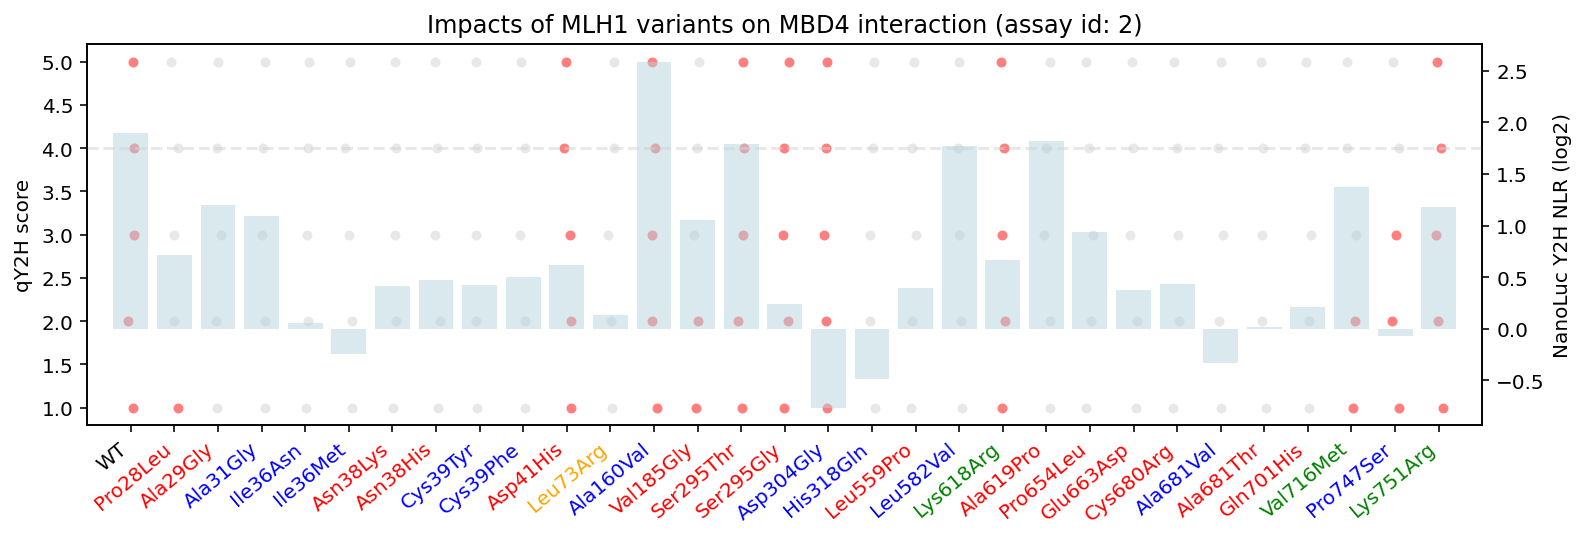

In [88]:
df = normalized_df.query("db_symbol == 'MLH1' and ad_symbol == 'MBD4' and db_mut_id != 461.0").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)

qY2H_media_d = {'LWH1':1,
                'LWH10':2,
                'LWH25':3,
                'LWA':4,
                'LWAH1':5}


for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    df[f'{media}_s'] = qY2H_media_d[media]
    df[f'{media}_c'] = df[media].apply(lambda x: x[-1] if x == x else np.nan)

fig, ax1 = plt.subplots(figsize=(12.5,3.5))

ax1.set_title(f'Impacts of MLH1 variants on MBD4 interaction (assay id: {df.assay_id.tolist()[0]})')
#ax1.set_ylim(3.5,5.5)
ax2 = ax1.twinx()
#ax2.set_ylim(-1,3)

for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    g = sns.stripplot(data=df, y=f'{media}_s', hue=f'{media}_c',x='aa_change', palette={0:'lightgrey',1:'red','AA':'lightpink'}, ax=ax1, alpha=0.5)


g = sns.barplot(data=df, y='nY2H_NLR',x='aa_change', ax=ax2, color='lightblue', alpha=0.5)#, hue='nY2H_d', palette={True:'lightblue', False:'lightgrey'})

ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
ax1.set_xlabel('')
ax1.set_xlim(-1,len(df))
ax1.set_ylabel('qY2H score')
ax2.set_ylabel('NanoLuc Y2H NLR (log2)')

ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey', alpha=0.5)

cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
#cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
for xtick in ax1.get_xticklabels():
    xtick.set_color(colors_d[xtick.get_text()])
    
ax1.get_legend().remove()
#ax2.get_legend().remove()
plt.savefig(f'figures/qY2H_nY2H_{"MLH1_MBD4"}.png', bbox_inches='tight', dpi=300)
plt.show()
#df.head()

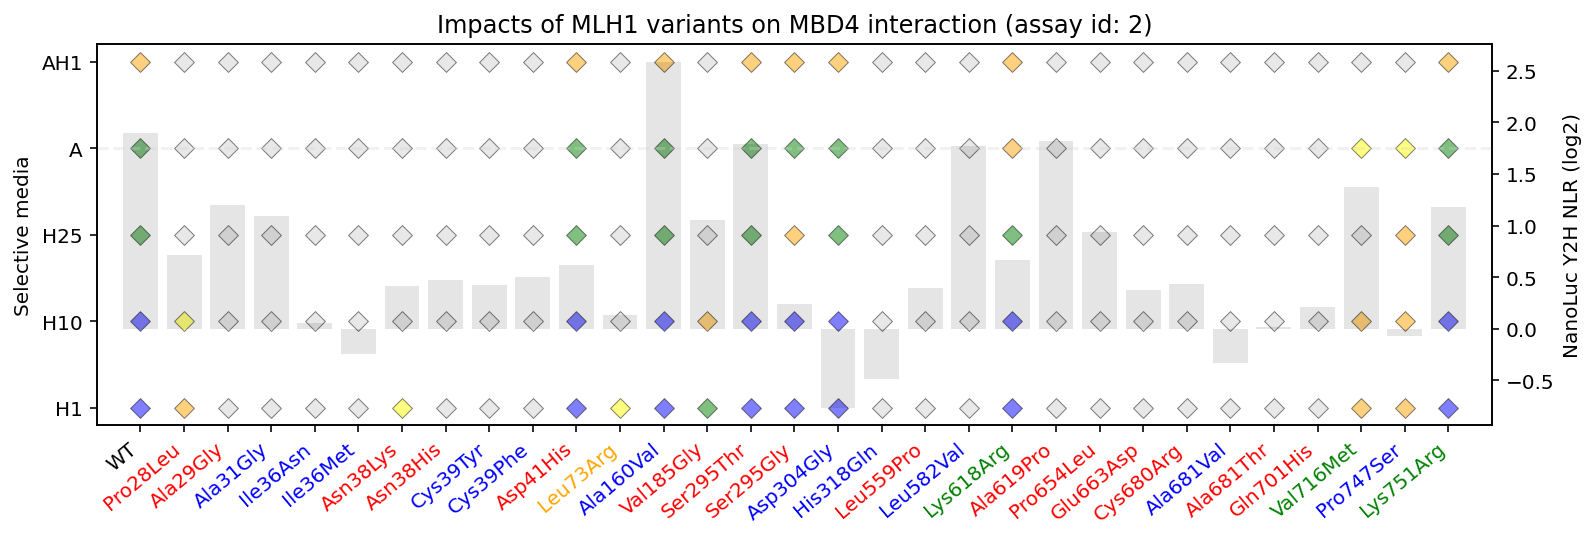

In [89]:
df = normalized_df.query("db_symbol == 'MLH1' and ad_symbol == 'MBD4' and db_mut_id != 461.0").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)

qY2H_media_d = {'LWH1':1,
                'LWH10':2,
                'LWH25':3,
                'LWA':4,
                'LWAH1':5}


for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    df[f'{media}_s'] = qY2H_media_d[media]
    df[f'{media}_c'] = df[media].apply(lambda x: x[0] if (x[-1] != 'AA') or (x[-1] == x[-1]) else x[-1] if x == x else np.nan)

fig, ax1 = plt.subplots(figsize=(12.5,3.5))

ax1.set_title(f'Impacts of MLH1 variants on MBD4 interaction (assay id: {df.assay_id.tolist()[0]})')
#ax1.set_ylim(3.5,5.5)
ax2 = ax1.twinx()
#ax2.set_ylim(-1,3)

g = sns.barplot(data=df, y='nY2H_NLR',x='aa_change', ax=ax2, color='black', alpha=0.1, linewidth=2)#, hue='nY2H_d', palette={True:'lightblue', False:'lightgrey'})
for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    g = sns.stripplot(data=df, y=f'{media}_s', hue=f'{media}_c',x='aa_change', palette={0:'lightgrey',
                                                                                        1:'yellow',
                                                                                        2:'orange',
                                                                                        3:'green',
                                                                                        4:'blue',
                                                                                        'AA':'lightpink'}, ax=ax1, alpha=0.5, size=7, jitter=False, marker="D",linewidth=0.5, edgecolor='black')


ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
ax1.set_xlabel('')
ax1.set_xlim(-1,len(df))
ax1.set_ylabel('Selective media')
ax2.set_ylabel('NanoLuc Y2H NLR (log2)')

ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey', alpha=0.3)

cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
#cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
for xtick in ax1.get_xticklabels():
    xtick.set_color(colors_d[xtick.get_text()])
    
positions = [1, 2, 3, 4, 5]
labels = ['H1', 'H10', 'H25', 'A', 'AH1']
ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
ax1.yaxis.set_major_formatter(ticker.FixedFormatter(labels))

ax1.get_legend().remove()
#ax2.get_legend().remove()
#plt.savefig(f'figures/qY2H_nY2H_{"MLH1_MBD4"}.png', bbox_inches='tight', dpi=300)
plt.show()
#df.head()

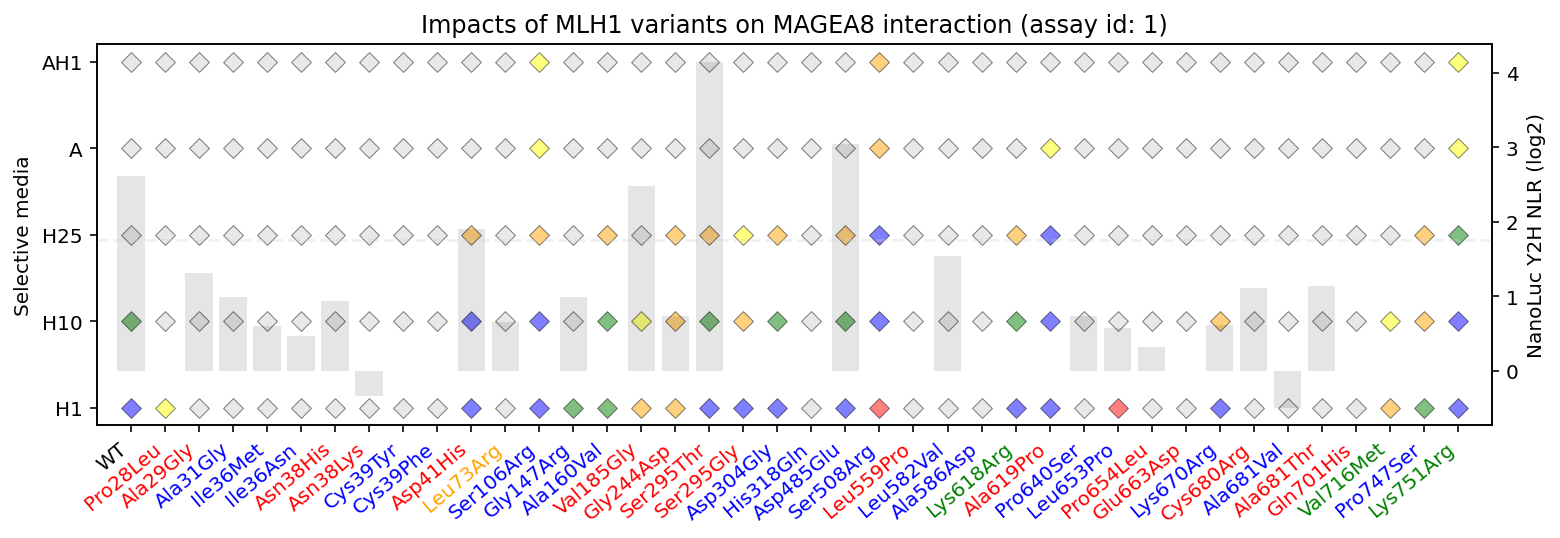

In [90]:
df = normalized_df.query("db_symbol == 'MLH1' and ad_symbol == 'MAGEA8' and db_mut_id != 461.0").copy()
df.sort_values(by='mut_pos', ascending=True, inplace=True)

qY2H_media_d = {'LWH1':1,
                'LWH10':2,
                'LWH25':3,
                'LWA':4,
                'LWAH1':5}


for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    df[f'{media}_s'] = qY2H_media_d[media]
    df[f'{media}_c'] = df[media].apply(lambda x: x[0] if (x[-1] != 'AA') or (x[-1] != x[-1]) else x[-1] if x == x else np.nan)

fig, ax1 = plt.subplots(figsize=(12.5,3.5))

ax1.set_title(f'Impacts of MLH1 variants on MAGEA8 interaction (assay id: {df.assay_id.tolist()[0]})')
#ax1.set_ylim(3.5,5.5)
ax2 = ax1.twinx()
#ax2.set_ylim(-1,3)

g = sns.barplot(data=df, y='nY2H_NLR',x='aa_change', ax=ax2, color='black', alpha=0.1, linewidth=2)#, hue='nY2H_d', palette={True:'lightblue', False:'lightgrey'})
for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
    g = sns.stripplot(data=df, y=f'{media}_s', hue=f'{media}_c',x='aa_change', palette={0:'lightgrey',0.75:'lightgrey',
                                                                                        1:'yellow',1.75:'yellow',
                                                                                        2:'orange',
                                                                                        3:'green',3.75:'green',
                                                                                        4:'blue',
                                                                                        'AA':'red'}, ax=ax1, alpha=0.5, size=7, jitter=False, marker="D",linewidth=0.5, edgecolor='black')


ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
ax1.set_xlabel('')
ax1.set_xlim(-1,len(df))
ax1.set_ylabel('Selective media')
ax2.set_ylabel('NanoLuc Y2H NLR (log2)')

ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey', alpha=0.3)

cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
#cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
for xtick in ax1.get_xticklabels():
    xtick.set_color(colors_d[xtick.get_text()])
    
positions = [1, 2, 3, 4, 5]
labels = ['H1', 'H10', 'H25', 'A', 'AH1']
ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
ax1.yaxis.set_major_formatter(ticker.FixedFormatter(labels))

ax1.get_legend().remove()
#ax2.get_legend().remove()
#plt.savefig(f'figures/qY2H_nY2H_{"MLH1_MAGEA8"}.png', bbox_inches='tight', dpi=300)
plt.show()
#df.head()

In [91]:
df

,ad_orf_id,db_orf_id,db_mut_id,standard_batch,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,db_symbol,ad_symbol,nt_change,aa_change,clinical_significance,mut_pos,nY2H_NLR,nY2H_d,pDEST_ratio,pDEST_s,LWH1_s,LWH1_c,LWH10_s,LWH10_c,LWH25_s,LWH25_c,LWA_s,LWA_c,LWAH1_s,LWAH1_c
25,6552,2713,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,MLH1,MAGEA8,WT,WT,WT,0,2.617302,True,NaN,NaN,1,4.0,2,3.00,3,0.0,4,0.00,5,0.0
2033,6552,2713,449,VUSAPWT1B1,1,"[4.0, 4.0, True]","[1.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,83C>T,Pro28Leu,Pathogenic,28,NaN,False,NaN,NaN,1,1.0,2,0.00,3,0.0,4,0.00,5,0.0
2046,6552,2713,451,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,86C>G,Ala29Gly,Pathogenic,29,1.306033,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2059,6552,2713,455,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,92C>G,Ala31Gly,VUS,31,0.995612,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2085,6552,2713,462,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,108T>G,Ile36Met,VUS,36,0.605874,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2888,6552,2713,200798,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,107T>A,Ile36Asn,VUS,36,0.471979,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2098,6552,2713,467,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,112A>C,Asn38His,Pathogenic,38,0.931113,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2111,6552,2713,470,VUSAPWT1B1,1,"[3.25, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,114C>G,Asn38Lys,Pathogenic,38,-0.337317,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2124,6552,2713,472,VUSAPWT1B1,1,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,116G>A,Cys39Tyr,VUS,39,NaN,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0
2137,6552,2713,473,VUSAPWT1B1,1,"[3.75, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,MLH1,MAGEA8,116G>T,Cys39Phe,VUS,39,NaN,False,NaN,NaN,1,0.0,2,0.00,3,0.0,4,0.00,5,0.0


In [92]:
xx

NameError: name 'xx' is not defined

In [ ]:
# from os import system

# for db_symbol in ['MLH1','STXBP1']:
#     #system(f'mkdir {db_symbol}')
#     for ad_symbol in normalized_df.query(f"db_symbol == '{db_symbol}'").ad_symbol.unique():
#         df = normalized_df.query(f"db_symbol == '{db_symbol}' and ad_symbol == '{ad_symbol}' and db_mut_id != 461.0").copy()
#         df.sort_values(by='mut_pos', ascending=True, inplace=True)

#         qY2H_media_d = {'LWH1':1,
#                         'LWH10':2,
#                         'LWH25':3,
#                         'LWA':4,
#                         'LWAH1':5}


#         for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
#             df[f'{media}_s'] = qY2H_media_d[media]
#             df[f'{media}_c'] = df[media].apply(lambda x: x[-1] if x == x else np.nan)

#         fig, ax1 = plt.subplots(figsize=(12.5,3.5))

#         ax1.set_title(f'Impacts of {db_symbol} variants on {ad_symbol} interaction (assay id: {df.assay_id.tolist()[0]})')
#         #ax1.set_ylim(3.5,5.5)
#         ax2 = ax1.twinx()
#         #ax2.set_ylim(-1,3)

#         for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
#             g = sns.stripplot(data=df, y=f'{media}_s', hue=f'{media}_c',x='aa_change', palette={0:'lightgrey',1:'red','AA':'green'}, ax=ax1, alpha=0.5)


#         g = sns.barplot(data=df, y='nY2H_NLR',x='aa_change', ax=ax2, color='lightblue', alpha=0.5)#, hue='nY2H_d', palette={True:'lightblue', False:'lightgrey'})

#         ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
#         ax1.set_xlabel('')
#         ax1.set_xlim(-1,len(df))
#         ax1.set_ylabel('qY2H score')
#         ax2.set_ylabel('NanoLuc Y2H NLR (log2)')

#         ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey', alpha=0.5)

#         cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
#         #cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
#         colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
#         for xtick in ax1.get_xticklabels():
#             xtick.set_color(colors_d[xtick.get_text()])
            
#         positions = [1, 2, 3, 4, 5]
#         labels = ['H1', 'H10', 'H25', 'A', 'AH1']
#         ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
#         ax1.yaxis.set_major_formatter(ticker.FixedFormatter(labels))

#         ax1.get_legend().remove()
#         #ax2.get_legend().remove()
#         plt.savefig(f'figures/{db_symbol}/qY2H_nY2H_{db_symbol}_{ad_symbol}.png', bbox_inches='tight', dpi=300)
#         plt.close(fig)

In [ ]:
from os import system
for db_symbol in ['MLH1','STXBP1']:
    for ad_symbol in normalized_df.query(f"db_symbol == '{db_symbol}'").ad_symbol.unique():
        df = normalized_df.query(f"db_symbol == '{db_symbol}' and ad_symbol == '{ad_symbol}' and db_mut_id != 461.0").copy()
        df.sort_values(by='mut_pos', ascending=True, inplace=True)

        qY2H_media_d = {'LWH1':1,
                        'LWH10':2,
                        'LWH25':3,
                        'LWA':4,
                        'LWAH1':5}


        for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
            df[f'{media}_s'] = qY2H_media_d[media]
            df[f'{media}_c'] = df[media].apply(lambda x: x[0] if (x[-1] != 'AA') or (x[-1] != x[-1]) else x[-1] if x == x else np.nan)

        fig, ax1 = plt.subplots(figsize=(12.5,3.5))

        ax1.set_title(f'Impacts of {db_symbol} variants on {ad_symbol} interaction (assay id: {df.assay_id.tolist()[0]})')
        #ax1.set_ylim(3.5,5.5)
        ax2 = ax1.twinx()
        #ax2.set_ylim(-1,3)

        g = sns.barplot(data=df, y='nY2H_NLR',x='aa_change', ax=ax2, color='black', alpha=0.1, linewidth=2)#, hue='nY2H_d', palette={True:'lightblue', False:'lightgrey'})
        for media in ['LWH1','LWH10','LWH25','LWA','LWAH1']:
            g = sns.stripplot(data=df, y=f'{media}_s', hue=f'{media}_c',x='aa_change', palette={0:'lightgrey',0.5:'lightgrey',0.66667:'lightgrey',
                                                                                                1:'yellow',0.75:'yellow',1.75:'yellow',1.5:'yellow',1.25:'yellow',1.33333:'yellow',1.66667:'yellow',
                                                                                                2:'orange',2.5:'orange',2.25:'orange',2.75:'orange',2.66667:'orange',2.33333:'orange',
                                                                                                3:'green',3.75:'green',3.66667:'green',3.25:'green',3.5:'green',3.33333:'green',
                                                                                                4:'blue',
                                                                                                'AA':'red'}, ax=ax1, alpha=0.5, size=7, jitter=False, marker="D",linewidth=0.5, edgecolor='black')


        ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha='right')
        ax1.set_xlabel('')
        ax1.set_xlim(-1,len(df))
        ax1.set_ylabel('Selective media')
        ax2.set_ylabel('NanoLuc Y2H NLR (log2)')

        ax2.hlines(xmin=-1,xmax=len(df),y=1.757, linestyle='--', color='lightgrey', alpha=0.3)

        cs_d = {'WT':'black', 'VUS':'blue','Pathogenic':'red','Benign':'green','Conflicting':'orange'}
        #cs_d = {'WT':'black', 'VUS':'grey','Pathogenic':'grey','Benign':'grey','Conflicting':'grey'}
        colors_d = dict(zip(df.aa_change, df.clinical_significance.map(cs_d)))
        for xtick in ax1.get_xticklabels():
            xtick.set_color(colors_d[xtick.get_text()])

        positions = [1, 2, 3, 4, 5]
        labels = ['H1', 'H10', 'H25', 'A', 'AH1']
        ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
        ax1.yaxis.set_major_formatter(ticker.FixedFormatter(labels))

        ax1.get_legend().remove()

        plt.savefig(f'figures/{db_symbol}/qY2H_nY2H_{db_symbol}_{ad_symbol}.png', bbox_inches='tight', dpi=300)
        plt.close(fig)
        #df.head()

## Merging perturbation and stability data together

In [93]:
col = ['ad_orf_id', 'db_orf_id', 'db_mut_id',
       'yN2H_score_rep1', 'yN2H_score_rep2', 'empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2',
       'empty_N2_rep2', 'NLR1', 'NLR2']

merge_yN2H_df = yN2H_df[col].copy()


merge_yN2H_df.rename(columns = {'yN2H_score_rep1':'yN2H_RLU_N1N2_R1',
                                'yN2H_score_rep2':'yN2H_RLU_N1N2_R2',
                                'empty_N1_rep1':'yN2H_RLU_EN1_R1',
                                'empty_N2_rep1':'yN2H_RLU_EN2_R1',
                                'empty_N1_rep2':'yN2H_RLU_EN1_R2',
                                'empty_N2_rep2':'yN2H_RLU_EN2_R2',
                                'NLR1':'yN2H_NLR1',
                                'NLR2':'yN2H_NLR2'}, inplace=True)



merge_yN2H_df.head()

,ad_orf_id,db_orf_id,db_mut_id,yN2H_RLU_N1N2_R1,yN2H_RLU_N1N2_R2,yN2H_RLU_EN1_R1,yN2H_RLU_EN2_R1,yN2H_RLU_EN1_R2,yN2H_RLU_EN2_R2,yN2H_NLR1,yN2H_NLR2
0,71963,2713,981.0,96,82,62,199,76,144,0.482412,0.569444
1,11452,4723,201730.0,336,103,117,137,124,110,2.452555,0.830645
2,361,3438,0.0,6558,2033,144,1174,220,1264,5.586031,1.608386
3,71892,71892,4005.0,1092,254,227,144,302,213,4.810573,0.841060
4,2500,2713,0.0,124,82,165,185,199,117,0.670270,0.412060


In [94]:
col = ['N1_orf_id', 'N2_orf_id', 'N2_mut_id','N1N2_xp1', 'N1N2_xp2',
       'empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2', 'NLR1',
       'NLR2']

merge_mN2H_df = mN2H_df[col].copy()


merge_mN2H_df.rename(columns = {'N1_orf_id':'ad_orf_id',
                                'N2_orf_id':'db_orf_id',
                                'N2_mut_id':'db_mut_id',
                                'N1N2_xp1':'mN2H_RLU_N1N2_R1',
                                'N1N2_xp2':'mN2H_RLU_N1N2_R2',
                                'empty_N1_xp1':'mN2H_RLU_EN1_R1',
                                'empty_N2_xp1':'mN2H_RLU_EN2_R1',
                                'empty_N1_xp2':'mN2H_RLU_EN1_R2',
                                'empty_N2_xp2':'mN2H_RLU_EN2_R2',
                                'NLR1':'mN2H_NLR1',
                                'NLR2':'mN2H_NLR2'}, inplace=True)


merge_mN2H_df.head()

,ad_orf_id,db_orf_id,db_mut_id,mN2H_RLU_N1N2_R1,mN2H_RLU_N1N2_R2,mN2H_RLU_EN1_R1,mN2H_RLU_EN2_R1,mN2H_RLU_EN1_R2,mN2H_RLU_EN2_R2,mN2H_NLR1,mN2H_NLR2
0,1108,5001,0,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,17.177984,17.647623
3,617,4447,0,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,4.007174,4.158825
6,3535,5887,0,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,17.180294,13.591274
9,3174,7186,0,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,0.386369,0.570607
12,273,5046,0,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,7.954820,10.921451


In [167]:
qy2h_col = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'assay_id',
       'LW', 'LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1', 'sum_score',
       'n_condition', 'allele_score_norm', 'wt_score_norm', 'valid',
       'nt_change', 'aa_change', 'clinical_significance'] 

nanoY2H_col = ['db_orf_id', 'db_symbol', 'db_mut_id', 'ad_orf_id', 'ad_symbol',
       'assay_id', 'RLU', 'RLU_log10',
       'RLU_ctrl', 'NLR', 'detected']

merged_df = normalized_df[qy2h_col].merge(nanoY2H_dataset_df[nanoY2H_col],on= ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'assay_id'],how='outer').copy()
merged_df = merged_df.merge(merge_yN2H_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'],how='outer')
merged_df = merged_df.merge(merge_mN2H_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'],how='outer')

merged_df['db_symbol'] = merged_df.db_orf_id.map(orf_to_symbol)
merged_df['ad_symbol'] = merged_df.ad_orf_id.map(orf_to_symbol)
merged_df['orf_pair'] = list(zip(merged_df.db_orf_id, merged_df.ad_orf_id))

merged_df['avg_NLR_mN2H'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) if (nlr1 == nlr1 and nlr2 == nlr2) else np.nan for nlr1, nlr2 in zip(merged_df.mN2H_NLR1, merged_df.mN2H_NLR2)]
merged_df['avg_NLR_yN2H'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) if (nlr1 == nlr1 and nlr2 == nlr2) else np.nan for nlr1, nlr2 in zip(merged_df.yN2H_NLR1, merged_df.yN2H_NLR2)]

col = ['ad_orf_id', 'db_orf_id', 'orf_pair', 'db_mut_id', 'assay_id', 'LW', 'LWH1',
       'LWH10', 'LWH25', 'LWA', 'LWAH1', 'sum_score', 'n_condition',
       'allele_score_norm', 'wt_score_norm', 'valid', 'nt_change', 'aa_change',
       'clinical_significance', 'db_symbol', 'ad_symbol', 'NLR', 
       'yN2H_NLR1', 'yN2H_NLR2', 'mN2H_NLR1', 'mN2H_NLR2','avg_NLR_mN2H','avg_NLR_yN2H','detected']

merged_df = merged_df[col].copy()

#detection threshold mN2H ≥ 32.8
#detection threshold mN2H ≥ 1.35

merged_df.drop(columns=['mN2H_NLR1','mN2H_NLR2','yN2H_NLR1','yN2H_NLR2'], inplace=True)

#pdest_wt_normalized_d = {(orf_id,mut_id):(allele_wt_ratio,zscore,zcat)
merged_df['pdest_ratio'] = [pdest_wt_normalized_d[db_orf_id, db_mut_id][0] if (db_orf_id, db_mut_id) in pdest_wt_normalized_d else np.nan for db_orf_id, db_mut_id in zip(merged_df.db_orf_id,merged_df.db_mut_id)]
merged_df['pdest_zscore'] = [pdest_wt_normalized_d[db_orf_id, db_mut_id][0] if (db_orf_id, db_mut_id) in pdest_wt_normalized_d else np.nan for db_orf_id, db_mut_id in zip(merged_df.db_orf_id,merged_df.db_mut_id)]
merged_df['pdest_zcat'] = [pdest_wt_normalized_d[db_orf_id, db_mut_id][0] if (db_orf_id, db_mut_id) in pdest_wt_normalized_d else np.nan for db_orf_id, db_mut_id in zip(merged_df.db_orf_id,merged_df.db_mut_id)]

merged_df['d_mN2H'] = merged_df.avg_NLR_mN2H >= 32.8 
merged_df['d_yN2H'] = merged_df.avg_NLR_mN2H >= 1.35
merged_df.rename(columns={'detected':'d_nanoY2H'},inplace=True)
merged_df['d_ade'] = [np.nan if lw != lw else lw[-1] and (lwa[-1] == 1 or lwah[-1] == 1)  for lw, lwa, lwah in zip(merged_df.LW, merged_df.LWA, merged_df.LWAH1)]

merged_df['d_his1'] = [np.nan if lw != lw else lw[-1] and (lwh1[-1] == 1)  for lw, lwh1 in zip(merged_df.LW, merged_df.LWH1)]
merged_df['d_his10'] = [np.nan if lw != lw else lw[-1] and (lwh10[-1] == 1)  for lw, lwh10 in zip(merged_df.LW, merged_df.LWH10)]
merged_df['d_his25'] = [np.nan if lw != lw else lw[-1] and (lwh25[-1] == 1)  for lw, lwh25 in zip(merged_df.LW, merged_df.LWH25)]

merged_df['q3AT'] = [np.nan if lw != lw else np.sum([e for e in [h1[-1],h10[-1],h25[-1]] if e in [0,1]]) if lw[-1] else np.nan for lw,h1,h10,h25 in zip(merged_df.LW, merged_df.LWH1, merged_df.LWH10, merged_df.LWH25)]
q3AT_wt_d = dict(zip(merged_df[merged_df.db_mut_id == 0].orf_pair, merged_df[merged_df.db_mut_id == 0].q3AT))
merged_df['WT_q3AT'] = merged_df.orf_pair.map(q3AT_wt_d)

merged_df['n_media_q3AT'] = [np.nan if lw != lw else len([e for e in [h1[-1],h10[-1],h25[-1]] if e in [0,1]]) if lw[-1] else np.nan for lw,h1,h10,h25 in zip(merged_df.LW, merged_df.LWH1, merged_df.LWH10, merged_df.LWH25)]

merged_df['n_syst'] = [sum([e for e in [nano,mn2h,yn2h,ade] if e == e]) for nano,mn2h,yn2h,ade in zip (merged_df.d_nanoY2H, merged_df.d_mN2H, merged_df.d_yN2H, merged_df.d_ade)]
merged_df['lit_bm'] = [tuple(sorted([db,ad])) in litbm_set for db,ad in zip(merged_df.db_symbol, merged_df.ad_symbol)] 
merged_df['lit_bs'] = [tuple(sorted([db,ad])) in litbs_set for db,ad in zip(merged_df.db_symbol, merged_df.ad_symbol)] 

merged_df['perturb_class'] = ['NP' if allele == wt else 'P' if allele == 0 else 'MP' if allele < wt else 'G' for wt, allele in zip(merged_df.WT_q3AT, merged_df.q3AT)]
merged_df['q_perturb'] = [allele-wt for wt, allele in zip(merged_df.WT_q3AT, merged_df.q3AT)]

print(len(merged_df))
l = merged_df[(merged_df.db_mut_id == 0)&(merged_df.q3AT > 0)].orf_pair.unique()
merged_df = merged_df[(merged_df.n_media_q3AT == 3) & (merged_df.orf_pair.isin(l))].copy()

print(len(merged_df))
merged_df.head()

7542
4723


,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.07968,1.370158,NaN,False,NaN,NaN,NaN,False,True,False,True,True,False,2.0,2.0,3.0,1,False,False,NP,0.0
2,581.0,13295.0,"(13295.0, 581.0)",0.0,1.0,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,MAL2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0
3,869.0,13295.0,"(13295.0, 869.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,TTPA,CMTM5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,1.0,1.0,3.0,0,False,False,NP,0.0
4,7606.0,13295.0,"(13295.0, 7606.0)",0.0,1.0,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,TTPA,BIRC7,NaN,NaN,0.57692,NaN,NaN,NaN,NaN,False,False,True,True,True,True,3.0,3.0,3.0,1,False,False,NP,0.0
5,7845.0,13295.0,"(13295.0, 7845.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,AGTRAP,-0.65793,NaN,NaN,False,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0


In [169]:
merged_df.q_perturb.value_counts()

 0.0    2593
-3.0     629
-1.0     570
-2.0     540
 1.0     346
 2.0      45
Name: q_perturb, dtype: int64

In [168]:
merged_df.to_csv('edgotyping_y2h_n2h_pdest_table.tsv',sep='\t',index=False)

In [96]:
merged_df.q_perturb.value_counts()

 0.0    2593
-3.0     629
-1.0     570
-2.0     540
 1.0     346
 2.0      45
Name: q_perturb, dtype: int64

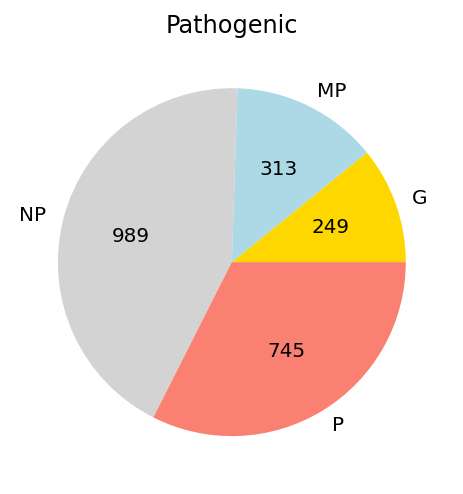

In [97]:
plt.figure()
plt.title('Pathogenic')
size = len(merged_df[merged_df.clinical_significance == 'Pathogenic'])
merged_df[merged_df.clinical_significance == 'Pathogenic'].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

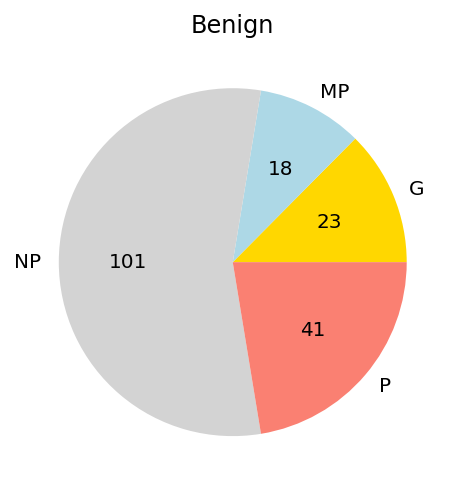

In [98]:
plt.figure()
plt.title('Benign')
size = len(merged_df[merged_df.clinical_significance == 'Benign'])
merged_df[merged_df.clinical_significance == 'Benign'].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

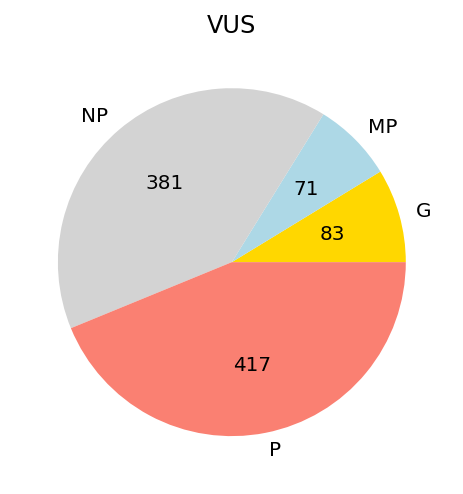

In [99]:
plt.figure()
plt.title('VUS')
size = len(merged_df[merged_df.clinical_significance == 'VUS'])
merged_df[merged_df.clinical_significance == 'VUS'].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

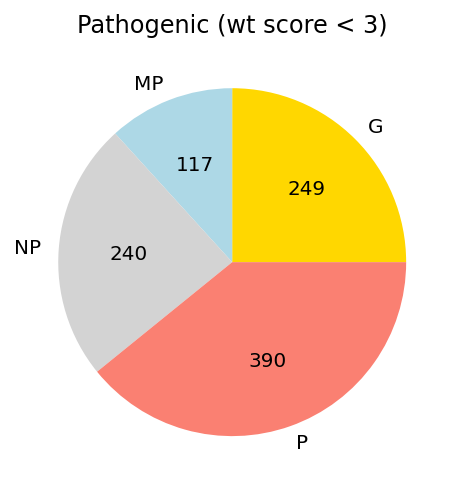

In [100]:
plt.figure()
plt.title('Pathogenic (wt score < 3)')
size = len(merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT < 3)])
merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT < 3)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

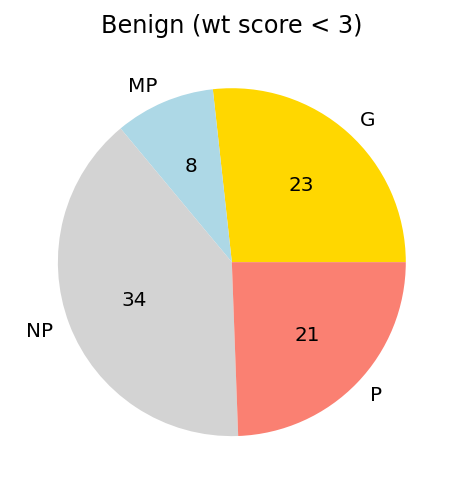

In [101]:
plt.figure()
plt.title('Benign (wt score < 3)')
size = len(merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT < 3)])
merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT < 3)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

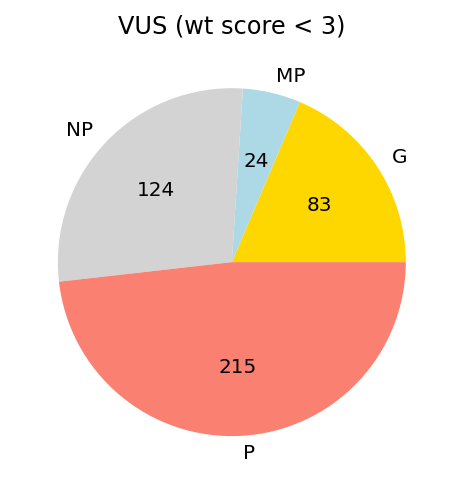

In [102]:
plt.figure()
plt.title('VUS (wt score < 3)')
size = len(merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT < 3)])
merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT < 3)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

In [103]:
merged_df[merged_df.db_mut_id > 0].db_orf_id.nunique()

114

In [104]:
merged_df.db_orf_id.nunique()

214

In [105]:
merged_df.clinical_significance.value_counts()

Pathogenic     2296
WT             1050
VUS             952
Conflicting     224
Benign          183
Name: clinical_significance, dtype: int64

In [106]:
merged_df[['db_orf_id','db_mut_id','clinical_significance']].drop_duplicates().clinical_significance.value_counts()

Pathogenic     489
WT             209
VUS            160
Conflicting     67
Benign          30
Name: clinical_significance, dtype: int64

In [107]:
merged_df.n_media_q3AT.value_counts()

3.0    4723
Name: n_media_q3AT, dtype: int64

In [108]:
merged_df.q3AT.value_counts()

3.0    2122
0.0    1323
2.0     710
1.0     568
Name: q3AT, dtype: int64

In [109]:
merged_df[merged_df.nt_change == 'WT'].lit_bm.value_counts()

False    994
True      56
Name: lit_bm, dtype: int64

In [110]:
merged_df.n_media_q3AT.value_counts()

3.0    4723
Name: n_media_q3AT, dtype: int64

In [111]:
merged_df[merged_df.nt_change == 'WT'].n_media_q3AT.value_counts()

3.0    1050
Name: n_media_q3AT, dtype: int64

In [112]:
merged_df[merged_df.nt_change == 'WT'].q3AT.value_counts()

3.0    675
2.0    240
1.0    135
Name: q3AT, dtype: int64

In [113]:
merged_df[merged_df.nt_change == 'WT'].n_syst.value_counts()

1    497
0    362
2    154
3     26
4     11
Name: n_syst, dtype: int64

### q3AT

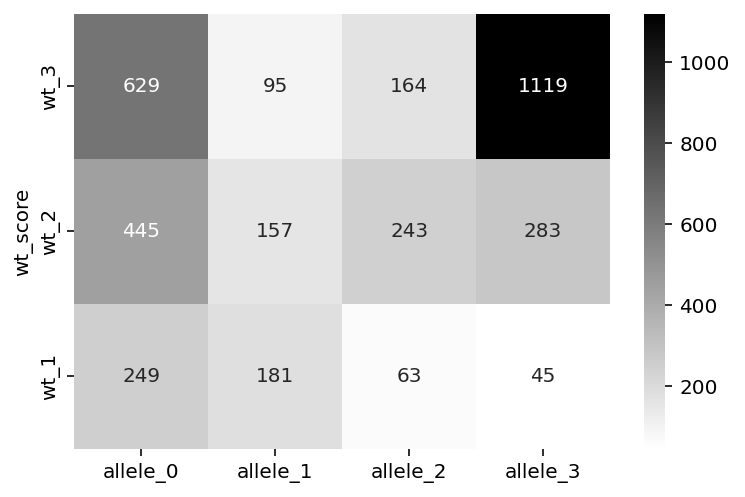

In [114]:
l = []
for wt_score in [3,2,1]:
    n_0 = ((merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 0)).sum()
    n_1 = ((merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 1)).sum()
    n_2 = ((merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 2)).sum()
    n_3 = ((merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 3)).sum()
    
    l.append([f'wt_{wt_score}',n_0,n_1,n_2,n_3])
    
df = pd.DataFrame(l, columns=['wt_score','allele_0','allele_1','allele_2','allele_3'])

plt.figure()
sns.heatmap(df.set_index('wt_score'), cmap='binary', annot=True,fmt='g')
plt.show()

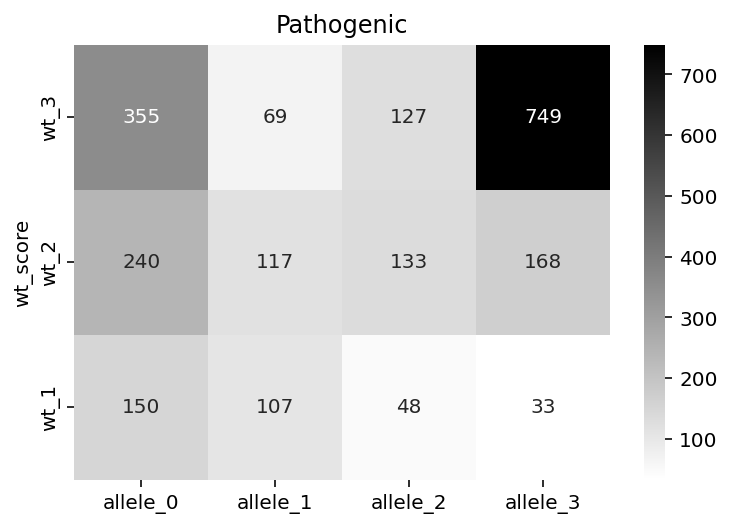

In [115]:
l = []
for wt_score in [3,2,1]:
    n_0 = ((merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 0)).sum()
    n_1 = ((merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 1)).sum()
    n_2 = ((merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 2)).sum()
    n_3 = ((merged_df.clinical_significance == 'Pathogenic')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 3)).sum()
    
    l.append([f'wt_{wt_score}',n_0,n_1,n_2,n_3])
    
df = pd.DataFrame(l, columns=['wt_score','allele_0','allele_1','allele_2','allele_3'])

plt.figure()
plt.title('Pathogenic')
sns.heatmap(df.set_index('wt_score'), cmap='binary', annot=True,fmt='g')
plt.show()

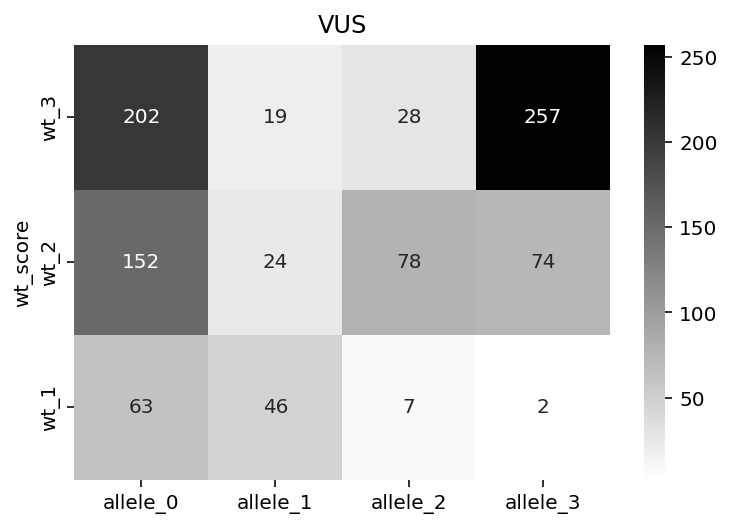

In [116]:
l = []
for wt_score in [3,2,1]:
    n_0 = ((merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 0)).sum()
    n_1 = ((merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 1)).sum()
    n_2 = ((merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 2)).sum()
    n_3 = ((merged_df.clinical_significance == 'VUS')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 3)).sum()
    
    l.append([f'wt_{wt_score}',n_0,n_1,n_2,n_3])
    
df = pd.DataFrame(l, columns=['wt_score','allele_0','allele_1','allele_2','allele_3'])

plt.figure()
plt.title('VUS')
sns.heatmap(df.set_index('wt_score'), cmap='binary', annot=True,fmt='g')
plt.show()

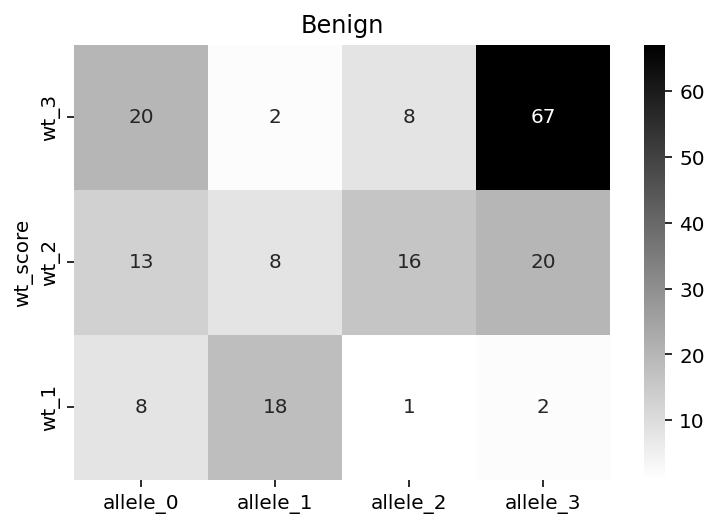

In [117]:
l = []
for wt_score in [3,2,1]:
    n_0 = ((merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 0)).sum()
    n_1 = ((merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 1)).sum()
    n_2 = ((merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 2)).sum()
    n_3 = ((merged_df.clinical_significance == 'Benign')&(merged_df.WT_q3AT == wt_score)&(merged_df.db_mut_id != 0)&(merged_df.q3AT == 3)).sum()
    
    l.append([f'wt_{wt_score}',n_0,n_1,n_2,n_3])
    
df = pd.DataFrame(l, columns=['wt_score','allele_0','allele_1','allele_2','allele_3'])

plt.figure()
plt.title('Benign')
sns.heatmap(df.set_index('wt_score'), cmap='binary', annot=True,fmt='g')
plt.show()

### Detectability

In [118]:
merged_df.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,d_mN2H,d_yN2H,d_ade,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.07968,1.370158,NaN,False,False,True,False,2.0,2.0,3.0,1,False,False,NP,0.0
2,581.0,13295.0,"(13295.0, 581.0)",0.0,1.0,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,MAL2,NaN,NaN,NaN,NaN,False,False,False,2.0,2.0,3.0,0,False,False,NP,0.0
3,869.0,13295.0,"(13295.0, 869.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,TTPA,CMTM5,NaN,NaN,NaN,NaN,False,False,False,1.0,1.0,3.0,0,False,False,NP,0.0
4,7606.0,13295.0,"(13295.0, 7606.0)",0.0,1.0,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,TTPA,BIRC7,NaN,NaN,0.57692,NaN,False,False,True,3.0,3.0,3.0,1,False,False,NP,0.0
5,7845.0,13295.0,"(13295.0, 7845.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,AGTRAP,-0.65793,NaN,NaN,False,False,False,False,2.0,2.0,3.0,0,False,False,NP,0.0


In [119]:
merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))].d_ade.value_counts(dropna=False)


True     332
False    268
Name: d_ade, dtype: int64

In [120]:
merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))].d_nanoY2H.value_counts(dropna=False)

False    346
True     185
NaN       69
Name: d_nanoY2H, dtype: int64

In [121]:
merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))].d_yN2H.value_counts(dropna=False)



False    541
True      59
Name: d_yN2H, dtype: int64

In [122]:
merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))].d_mN2H.value_counts(dropna=False)



False    562
True      38
Name: d_mN2H, dtype: int64

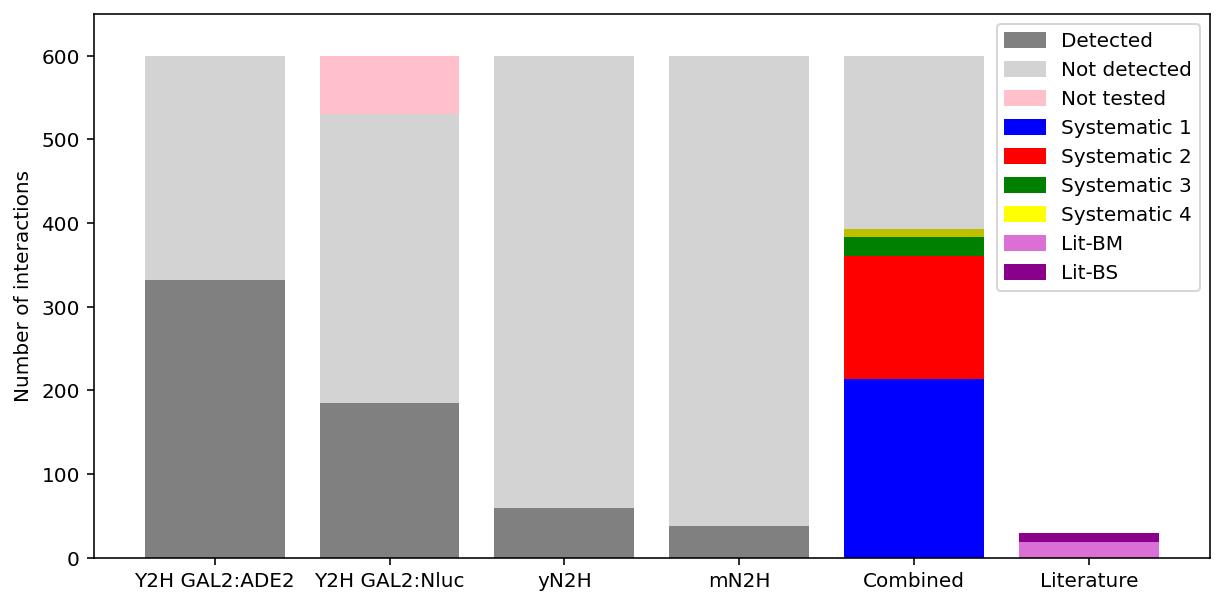

In [123]:
df = merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))]

x = ['Y2H GAL2:ADE2', 'Y2H GAL2:Nluc', 'yN2H', 'mN2H', 'Combined','Literature']

y1 =  np.array([df.d_ade.sum(), df.d_nanoY2H.sum(), df.d_yN2H.sum(), df.d_mN2H.sum(), (df.n_syst == 1).sum(), df.lit_bm.sum()])
y2 =  np.array([(df.d_ade==False).sum(),(df.d_nanoY2H==False).sum(),(df.d_yN2H==False).sum(),(df.d_mN2H==False).sum(),(df.n_syst == 2).sum(),df.lit_bs.sum()])
y3 =  np.array([0,(df.d_nanoY2H.isnull()).sum(),0,0,(df.n_syst == 3).sum(),0])
y4 =  np.array([0,0,0,0,(df.n_syst == 4).sum(),0])
y5 = np.array([0,0,0,0,(df.n_syst == 0).sum(),0])

plt.figure(figsize=(10,5))
plt.bar(x, y1, color=['gray','gray','gray','gray','blue','orchid'])
plt.bar(x, y2, color=['lightgray','lightgray','lightgray','lightgray','red','darkmagenta'], bottom=y1)
plt.bar(x, y3, color=['pink','pink','pink','pink','g','pink'], bottom=y1+y2)
plt.bar(x, y4, color='y', bottom=y1+y2+y3)
plt.bar(x, y5, color='lightgray', bottom=y1+y2+y3+y4)

plt.ylabel('Number of interactions')
plt.ylim(0,650)

import matplotlib.patches as mpatches

gray_patch = mpatches.Patch(color='gray', label='Detected')
lightgray_patch = mpatches.Patch(color='lightgray', label='Not detected')
pink_patch = mpatches.Patch(color='pink', label='Not tested')
blue_patch = mpatches.Patch(color='blue', label='Systematic 1')
red_patch = mpatches.Patch(color='red', label='Systematic 2')
green_patch = mpatches.Patch(color='green', label='Systematic 3')
yellow_patch = mpatches.Patch(color='yellow', label='Systematic 4')
orchid_patch = mpatches.Patch(color='orchid', label='Lit-BM')
darkmagenta_patch = mpatches.Patch(color='darkmagenta', label='Lit-BS')

#litbs_set

plt.legend(handles=[gray_patch,lightgray_patch,pink_patch,blue_patch,red_patch,green_patch,yellow_patch,orchid_patch,darkmagenta_patch])

plt.show()

In [143]:
merged_df.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.07968,1.370158,NaN,False,NaN,NaN,NaN,False,True,False,2.0,2.0,3.0,1,False,False,NP,0.0
2,581.0,13295.0,"(13295.0, 581.0)",0.0,1.0,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,MAL2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,2.0,2.0,3.0,0,False,False,NP,0.0
3,869.0,13295.0,"(13295.0, 869.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,TTPA,CMTM5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,1.0,1.0,3.0,0,False,False,NP,0.0
4,7606.0,13295.0,"(13295.0, 7606.0)",0.0,1.0,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,TTPA,BIRC7,NaN,NaN,0.57692,NaN,NaN,NaN,NaN,False,False,True,3.0,3.0,3.0,1,False,False,NP,0.0
5,7845.0,13295.0,"(13295.0, 7845.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,AGTRAP,-0.65793,NaN,NaN,False,NaN,NaN,NaN,False,False,False,2.0,2.0,3.0,0,False,False,NP,0.0


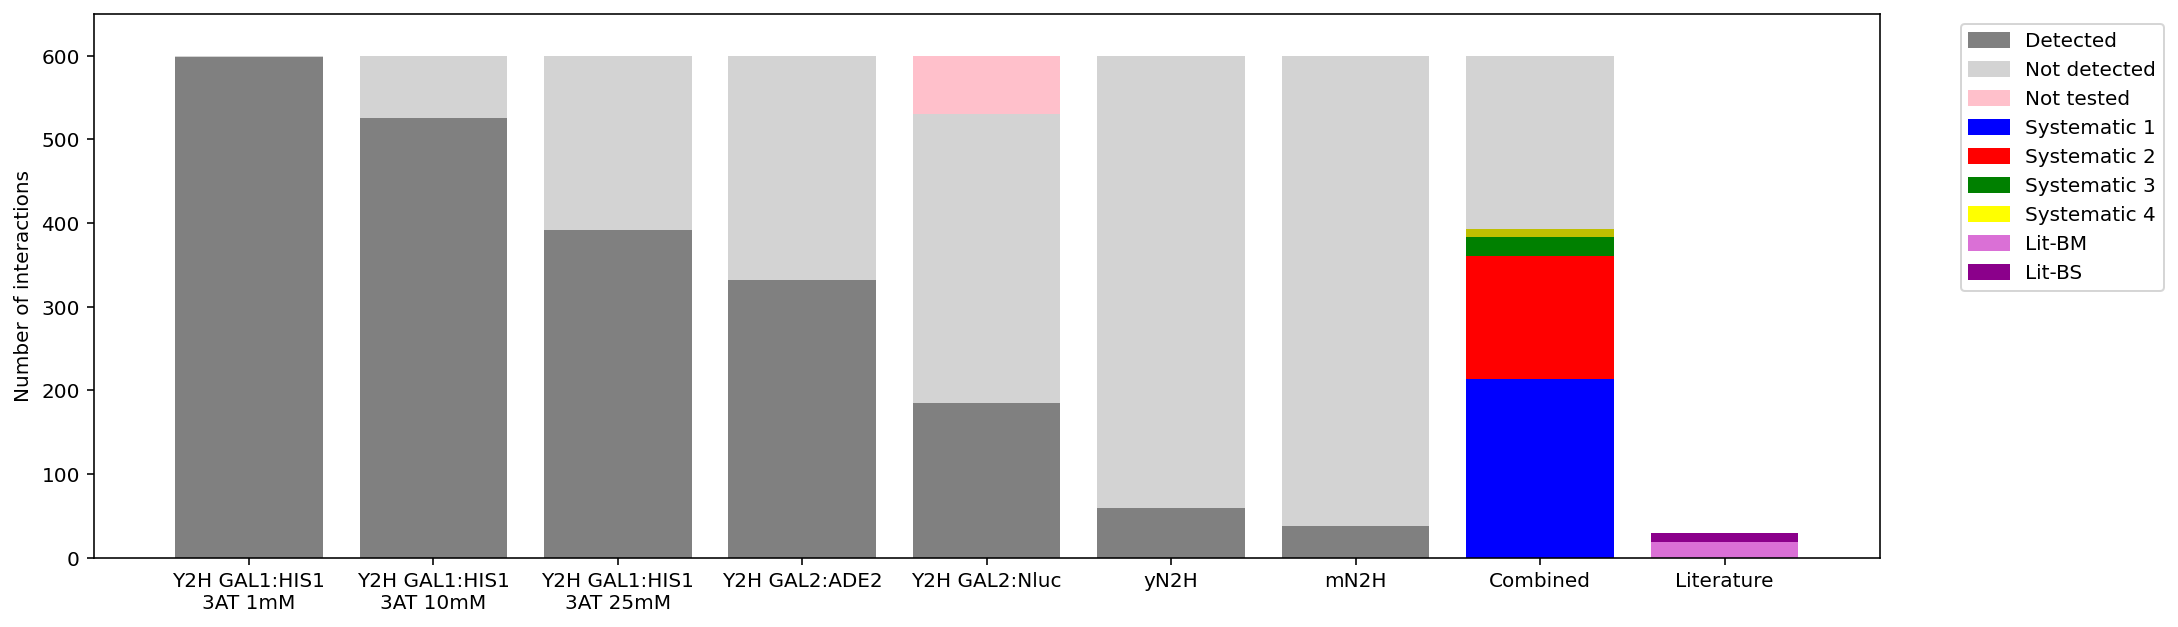

In [162]:
df = merged_df[(merged_df.db_mut_id == 0)&(merged_df.db_orf_id.isin(merged_df[merged_df.db_mut_id > 0].db_orf_id))]

x = ['Y2H GAL1:HIS1\n3AT 1mM',
     'Y2H GAL1:HIS1\n3AT 10mM',
     'Y2H GAL1:HIS1\n3AT 25mM',
     'Y2H GAL2:ADE2', 
     'Y2H GAL2:Nluc', 
     'yN2H', 
     'mN2H', 
     'Combined',
     'Literature']

y1 =  np.array([df.d_his1.sum(),df.d_his10.sum(),df.d_his25.sum(),df.d_ade.sum(), df.d_nanoY2H.sum(), df.d_yN2H.sum(), df.d_mN2H.sum(), (df.n_syst == 1).sum(), df.lit_bm.sum()])
y2 =  np.array([(df.d_his1==False).sum(),(df.d_his10==False).sum(),(df.d_his25==False).sum(),(df.d_ade==False).sum(),(df.d_nanoY2H==False).sum(),(df.d_yN2H==False).sum(),(df.d_mN2H==False).sum(),(df.n_syst == 2).sum(),df.lit_bs.sum()])
y3 =  np.array([0,0,0,0,(df.d_nanoY2H.isnull()).sum(),0,0,(df.n_syst == 3).sum(),0])
y4 =  np.array([0,0,0,0,0,0,0,(df.n_syst == 4).sum(),0])
y5 = np.array([0,0,0,0,0,0,0,(df.n_syst == 0).sum(),0])

plt.figure(figsize=(16,5))
plt.bar(x, y1, color=['gray','gray','gray','gray','gray','gray','gray','blue','orchid'])
plt.bar(x, y2, color=['lightgray','lightgray','lightgray','lightgray','lightgray','lightgray','lightgray','red','darkmagenta'], bottom=y1)
plt.bar(x, y3, color=['pink','pink','pink','pink','pink','pink','pink','g','pink'], bottom=y1+y2)
plt.bar(x, y4, color='y', bottom=y1+y2+y3)
plt.bar(x, y5, color='lightgray', bottom=y1+y2+y3+y4)

plt.ylabel('Number of interactions')
plt.ylim(0,650)

import matplotlib.patches as mpatches

gray_patch = mpatches.Patch(color='gray', label='Detected')
lightgray_patch = mpatches.Patch(color='lightgray', label='Not detected')
pink_patch = mpatches.Patch(color='pink', label='Not tested')
blue_patch = mpatches.Patch(color='blue', label='Systematic 1')
red_patch = mpatches.Patch(color='red', label='Systematic 2')
green_patch = mpatches.Patch(color='green', label='Systematic 3')
yellow_patch = mpatches.Patch(color='yellow', label='Systematic 4')
orchid_patch = mpatches.Patch(color='orchid', label='Lit-BM')
darkmagenta_patch = mpatches.Patch(color='darkmagenta', label='Lit-BS')

#litbs_set

plt.legend(handles=[gray_patch,lightgray_patch,pink_patch,blue_patch,red_patch,green_patch,yellow_patch,orchid_patch,darkmagenta_patch],
           bbox_to_anchor=(1.04, 1), loc="upper left"
          )

plt.show()

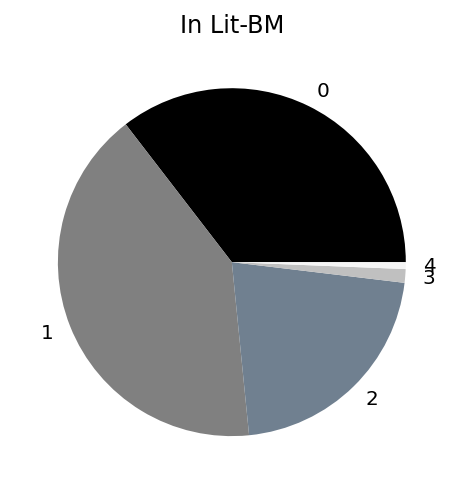

In [124]:
plt.title('In Lit-BM')
merged_df[merged_df.lit_bm == True].n_syst.value_counts().sort_index().plot.pie(colors=['black','gray','slategray','silver','whitesmoke'])
plt.ylabel('');

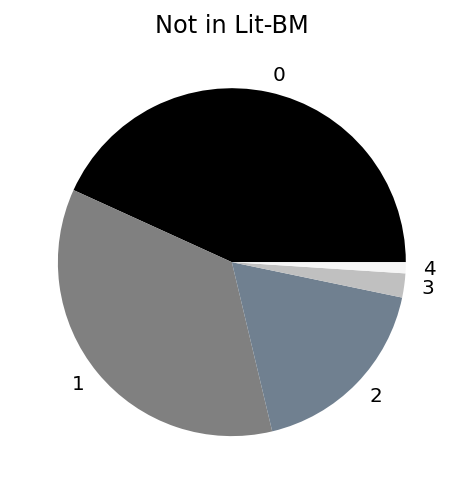

In [125]:
plt.title('Not in Lit-BM')
merged_df[merged_df.lit_bm == False].n_syst.value_counts().sort_index().plot.pie(colors=['black','gray','slategray','silver','whitesmoke'])
plt.ylabel('');

In [126]:
merged_df[merged_df.lit_bm == False].n_syst.value_counts().sort_index()

0    1972
1    1622
2     822
3     102
4      47
Name: n_syst, dtype: int64

In [127]:
merged_df[merged_df.lit_bm == True].n_syst.value_counts().sort_index()

0    56
1    65
2    34
3     2
4     1
Name: n_syst, dtype: int64

In [129]:
merged_df[(merged_df.n_syst == 0)&(merged_df.clinical_significance == 'Pathogenic')].perturb_class.value_counts()

P     578
NP    199
MP    126
G      71
Name: perturb_class, dtype: int64

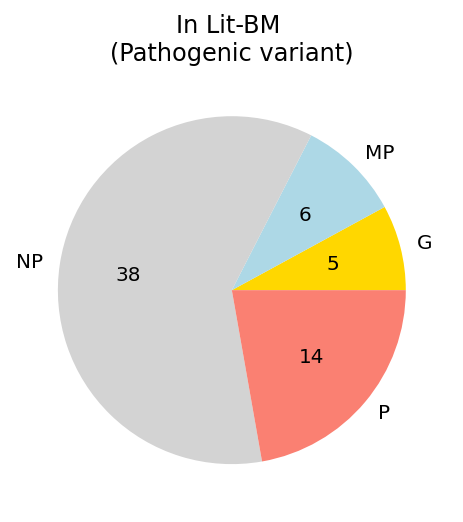

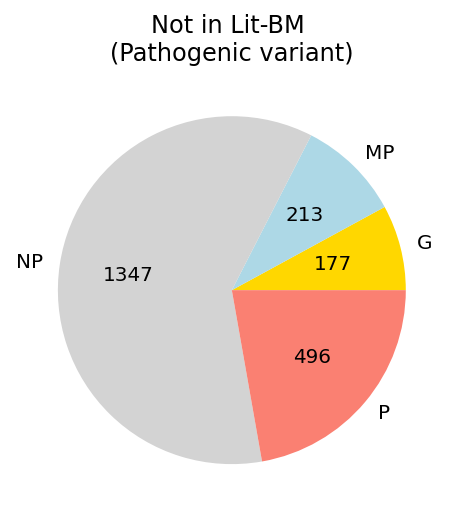

In [130]:
plt.figure()
plt.title(f'In Lit-BM \n(Pathogenic variant)')
size = len(merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.lit_bm == True)])

merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.lit_bm == True)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

plt.figure()
plt.title(f'Not in Lit-BM \n(Pathogenic variant)')
size = len(merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.lit_bm == False)])

merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.lit_bm == True)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

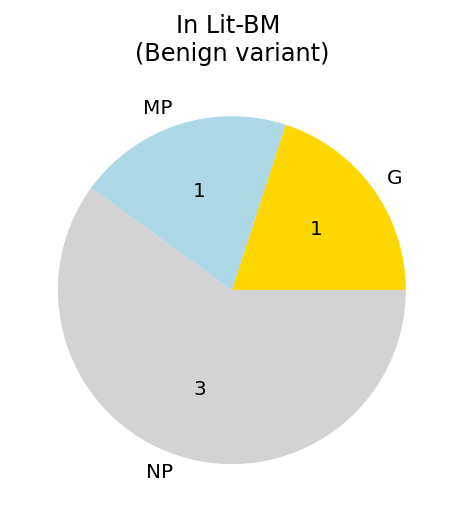

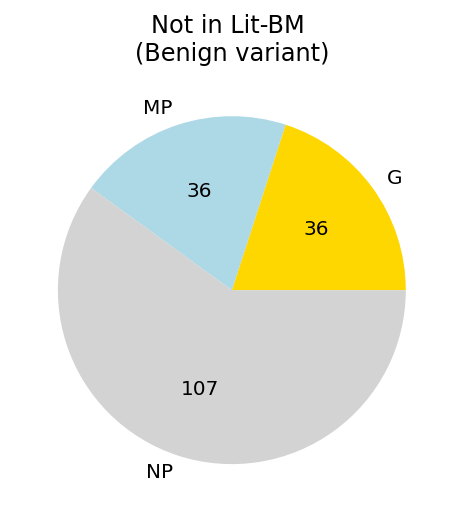

In [131]:
plt.figure()
plt.title(f'In Lit-BM \n(Benign variant)')
size = len(merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.lit_bm == True)])

merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.lit_bm == True)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

plt.figure()
plt.title(f'Not in Lit-BM \n(Benign variant)')
size = len(merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.lit_bm == False)])

merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.lit_bm == True)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

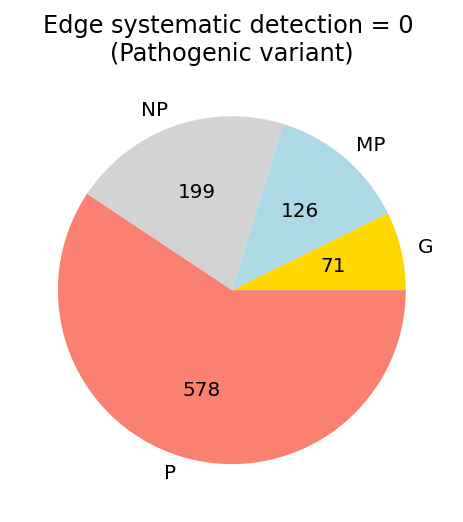

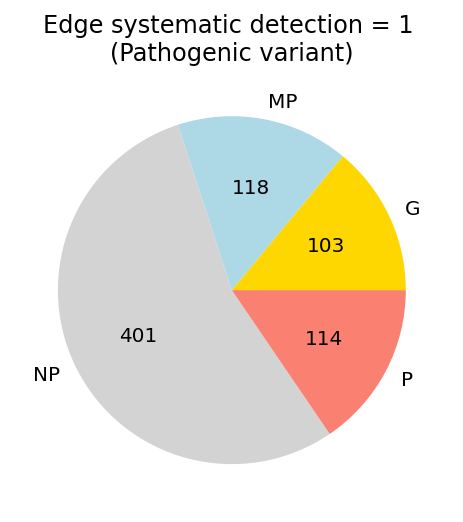

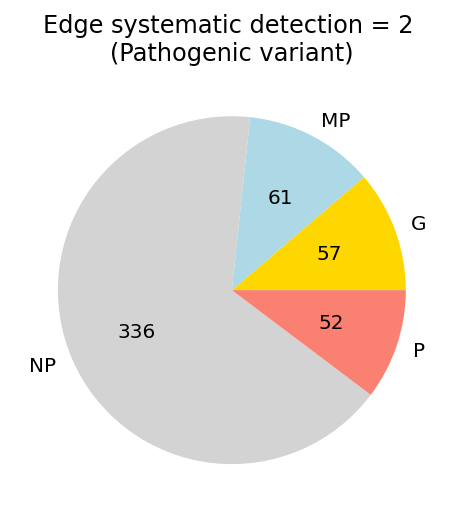

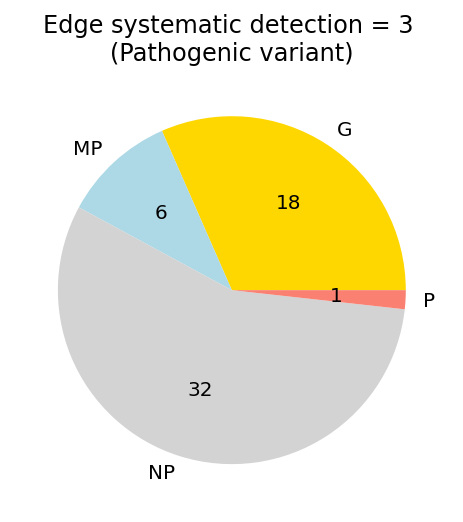

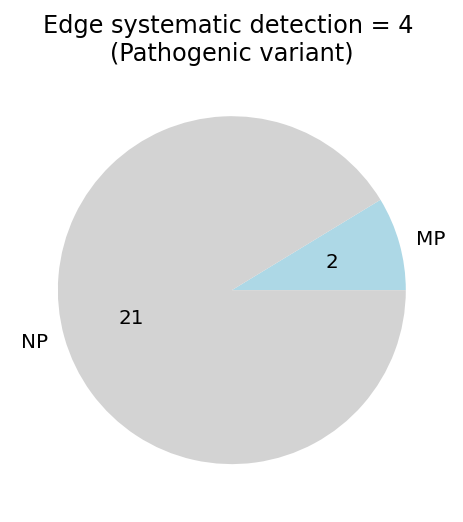

In [132]:
for n_syst in [0,1,2,3,4]:
    plt.figure()
    plt.title(f'Edge systematic detection = {n_syst} \n(Pathogenic variant)')
    size = len(merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.n_syst == n_syst)])
    if n_syst == 4:
        merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['lightblue','lightgray'])
    else:
        merged_df[(merged_df.clinical_significance == 'Pathogenic')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
    plt.ylabel('')
    plt.show()

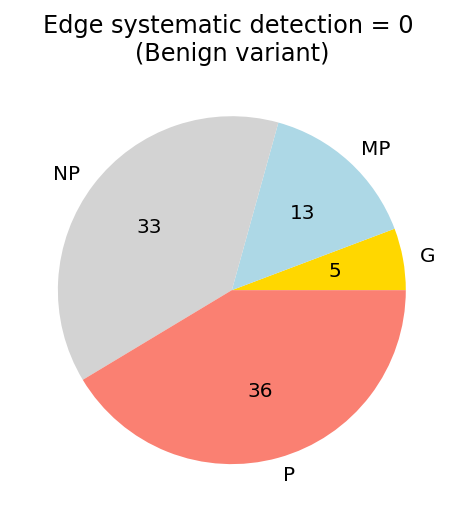

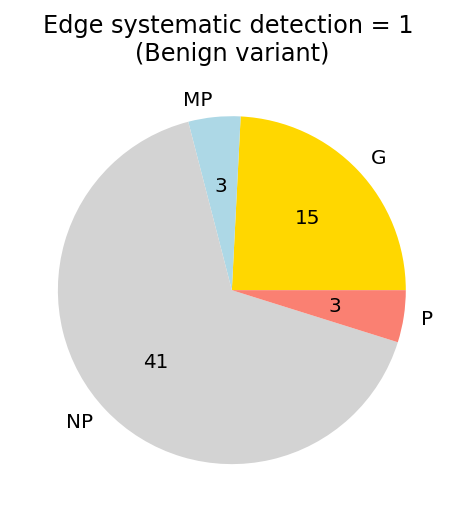

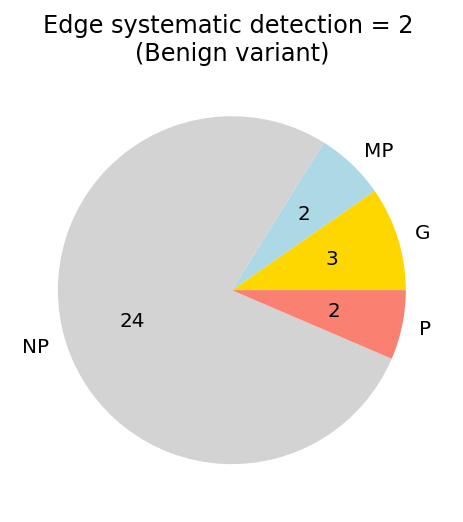

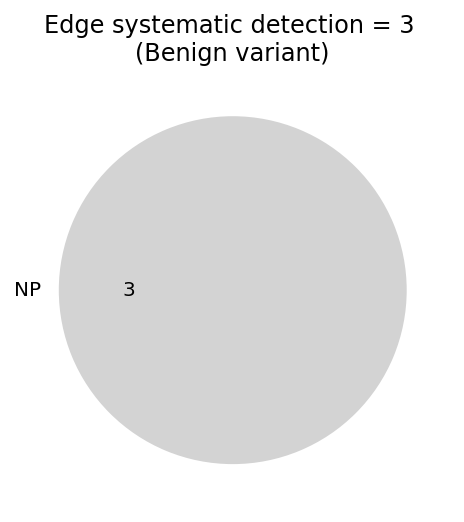

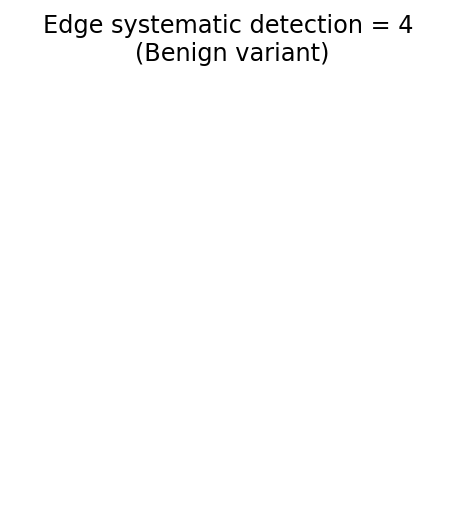

In [133]:
for n_syst in [0,1,2,3,4]:
    plt.figure()
    plt.title(f'Edge systematic detection = {n_syst} \n(Benign variant)')
    size = len(merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.n_syst == n_syst)])
    if n_syst == 3:
        merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['lightgray'])
    else:
        merged_df[(merged_df.clinical_significance == 'Benign')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
    plt.ylabel('')
    plt.show()

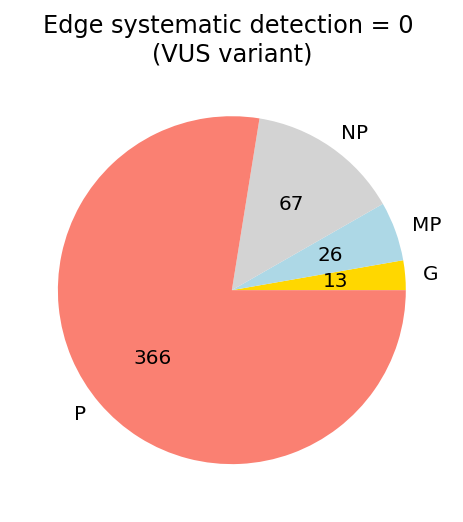

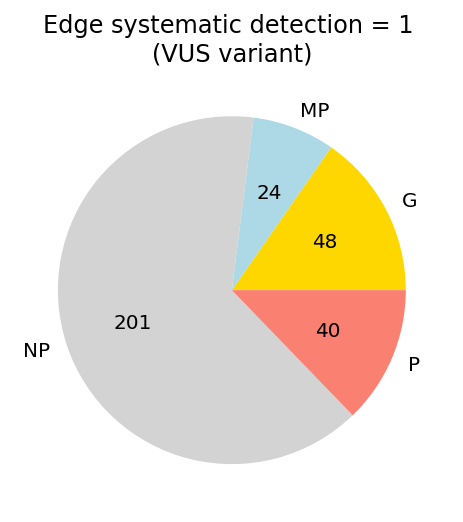

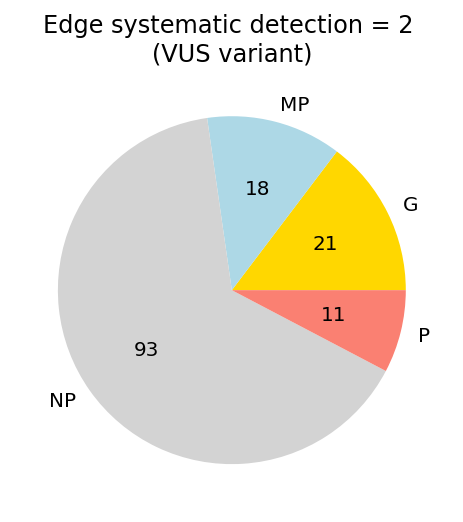

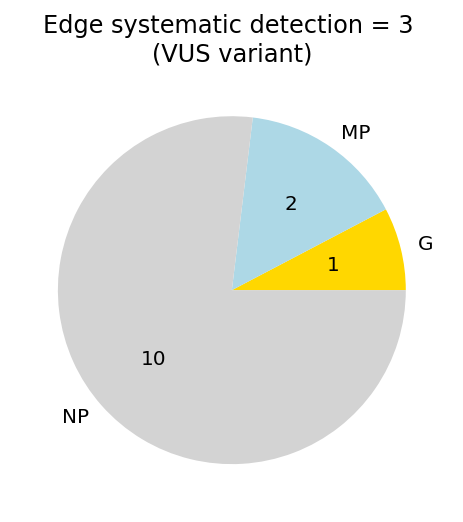

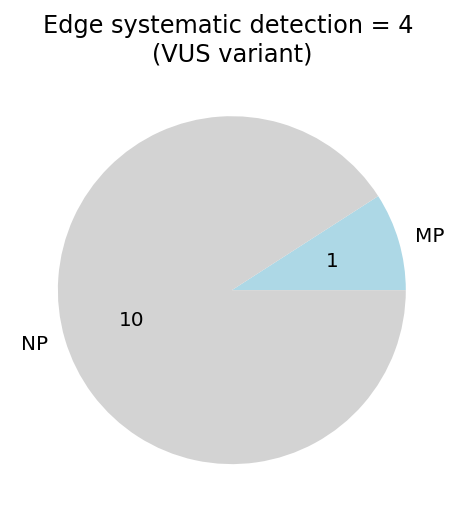

In [134]:
for n_syst in [0,1,2,3,4]:
    plt.figure()
    plt.title(f'Edge systematic detection = {n_syst} \n(VUS variant)')
    size = len(merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.n_syst == n_syst)])
    if n_syst == 4:
        merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['lightblue','lightgray'])
    else:
        merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.n_syst == n_syst)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
    plt.ylabel('')
    plt.show()

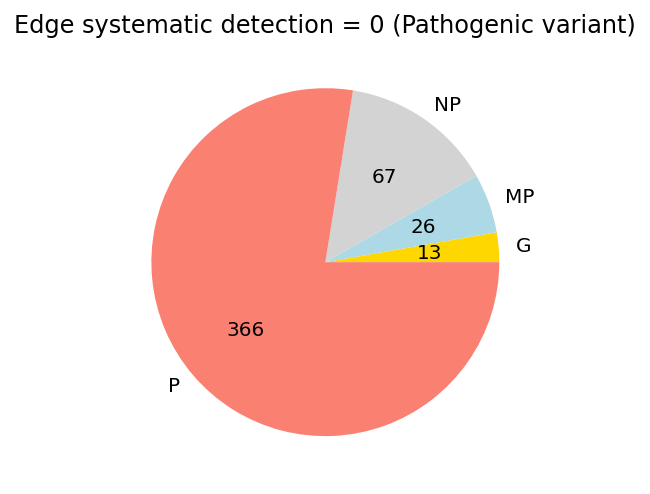

In [135]:
plt.figure()
plt.title('Edge systematic detection = 0 (Pathogenic variant)')
size = len(merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.n_syst == 0)])
merged_df[(merged_df.clinical_significance == 'VUS')&(merged_df.n_syst == 0)].perturb_class.value_counts().sort_index().plot.pie(autopct=lambda x: round((x/100)*size),colors = ['gold', 'lightblue','lightgray','salmon'])
plt.ylabel('')
plt.show()

In [ ]:
#merged_df.to_csv('edgotyping_spread_sheet_Y2H_nanoY2H_yN2H_mN2H.tsv', sep='\t')

In [ ]:
#merged_df.to_csv('/Users/georgescoppin/Desktop/edgotyping_spread_sheet_Y2H_nanoY2H_yN2H_mN2H.tsv', sep='\t')